# Tema 2 Machine Learning - Sentiment Analysis
## Mandescu Victor-Ioan 342C4

In [1]:
%pip install tensorflow
%pip install matplotlib Pillow scikit-learn seaborn spacy gensim nltk pandas tqdm
%pip install fasttext
%pip install transformers
!python -m spacy download ro_core_news_sm

import numpy as np
import os
import matplotlib.pyplot as plt
import random
import seaborn as sns
import spacy
import gensim
import string
import re
import pandas as pd
import nltk
import unicodedata
import tensorflow as tf
import torch
import torch.nn as nn
import torch.optim as optim

from IPython.lib.display import TextDisplayObject
from torch.utils.data import TensorDataset, DataLoader
from collections import defaultdict, Counter
from tqdm import tqdm

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, SpatialDropout1D
from tensorflow.keras.initializers import Constant
from tensorflow.keras.optimizers import Adam

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split

from nltk.corpus import stopwords
from nltk.util import ngrams
from nltk.tokenize import word_tokenize

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 93.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 4.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached pybind11-3.0.1-py3-none-any.whl.metadata (10.0 kB)
Using cached pybind11-3.0.1-py3-none-any.whl (293 kB)
  Created wheel for fasttext: filename=fasttext-0.9.3-cp312-cp312-linux_x86_64.whl size=4498215 sha256=120528399b21ceb17ffb687747640d9c69ba10e933a79aad32003e6d9c988eaf
  Stored in directory: /root/.cache/pip/wheels/20/27/95/a7baf1b435f1cbde017cabdf1e9688526d2b0e929255a359c6
Successfully built fasttext
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 73.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('ro_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart 

In [2]:
def remove_diacritics(text):
    text = text.lower()
    text = re.sub(r"\bsînt\w*", "sunt", text)
    text = text.replace("ş", "s").replace("ș", "s")
    text = text.replace("ţ", "t").replace("ț", "t")
    text = re.sub(r"(?<=[a-z0-9])î(?=[a-z0-9])", "â", text)
    text_clean = unicodedata.normalize('NFKD', text).encode('ASCII', 'ignore').decode('utf-8')

    return text_clean.lower()

In [3]:
nlp = spacy.load("ro_core_news_sm")
stop_words_default = nlp.Defaults.stop_words
stop_words_filtered = {remove_diacritics(w) for w in stop_words_default}

## 1. Exploratory Data Analysis

In [4]:
print(list(stop_words_default)[:30])
print(list(stop_words_filtered)[:30])

['alea', 'caut', 'pentru', 'azi', 'să', 'între', 'tale', 'aveţi', 'aceasta', 'ati', 'aceeași', 'fiţi', 'înaintea', 'nimeni', 'unui', 'or', 'nici', 'câte', 'niciodată', 'acestei', 'peste', 'nişte', 'oricât', 'trei', 'voştri', 'citi', 'încât', 'două', 'fiecare', 'degraba']
['alea', 'caut', 'pentru', 'azi', 'stiu', 'tale', 'aceasta', 'ati', 'tie', 'nimeni', 'unui', 'or', 'nici', 'multumesc', 'acestei', 'tai', 'peste', 'trei', 'citi', 'fiecare', 'degraba', 'exact', 'dat', 'ca', 'cati', 'una', 'ale', 'mereu', 'incat', 'cineva']


In [5]:
train_loader = pd.read_csv('train.csv')
test_loader = pd.read_csv('test.csv')

In [6]:
train_loader.head()

,index,text,label
0,0,acest document mi-a deschis cu adevarat ochii ...,1
1,1,tine mancarea rece. ce altceva ii mai trebuie?...,1
2,2,excelent\nrecomand!,1
3,3,"ca un rocker imbatranit, acest film mentioneaz...",1
4,4,"ei bine, a facut o groaza veche si foarte intu...",1


In [7]:
test_loader.head()

,Unnamed: 0,text,label
0,0,am vazut recent episoadele 1-4 si acum nu pot ...,1
1,1,anii cei mai buni ai vietii noastre capteaza p...,1
2,2,"aceasta apartine in clasa lor superioara, desi...",1
3,3,lucrare stralucitoare. actorii minunati se diz...,1
4,4,oamenii par sa se astepte la citizen kane aici...,1


In [8]:
test_loader.rename(columns={test_loader.columns[0]: 'index'}, inplace=True)
test_loader.head()

,index,text,label
0,0,am vazut recent episoadele 1-4 si acum nu pot ...,1
1,1,anii cei mai buni ai vietii noastre capteaza p...,1
2,2,"aceasta apartine in clasa lor superioara, desi...",1
3,3,lucrare stralucitoare. actorii minunati se diz...,1
4,4,oamenii par sa se astepte la citizen kane aici...,1


In [9]:
train_loader.shape

(17941, 3)

In [10]:
test_loader.shape

(11005, 3)

In [11]:
train_loader.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17941 entries, 0 to 17940
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   index   17941 non-null  int64 
 1   text    17651 non-null  object
 2   label   17941 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 420.6+ KB


In [12]:
test_loader.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11005 entries, 0 to 11004
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   index   11005 non-null  int64 
 1   text    11005 non-null  object
 2   label   11005 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 258.1+ KB


In [13]:
train_loader.isnull().sum()

,0
index,0
text,290
label,0


In [14]:
test_loader.isnull().sum()

,0
index,0
text,0
label,0


In [15]:
train_loader.dropna(subset=['text'], inplace=True)
train_loader.isnull().sum()

,0
index,0
text,0
label,0


In [16]:
train_loader.duplicated().sum()

np.int64(0)

In [17]:
test_loader.duplicated().sum()

np.int64(0)

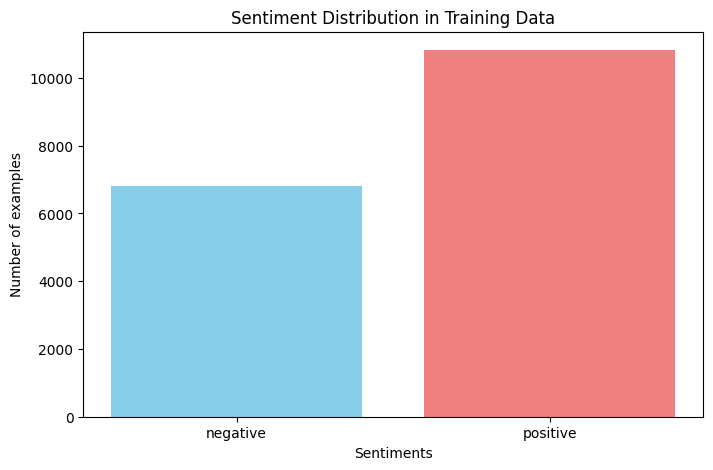

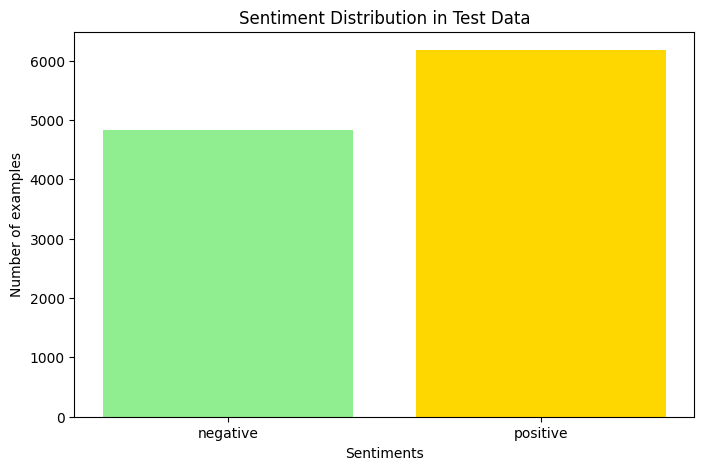

In [18]:
labels = ["negative", "positive"]
values_train = train_loader['label'].value_counts().sort_index().values
values_test = test_loader['label'].value_counts().sort_index().values

plt.figure(figsize=(8, 5))
plt.bar(labels, values_train, color=['skyblue', 'lightcoral'])
plt.xlabel('Sentiments')
plt.ylabel('Number of examples')
plt.title('Sentiment Distribution in Training Data')
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(labels, values_test, color=['lightgreen', 'gold'])
plt.xlabel('Sentiments')
plt.ylabel('Number of examples')
plt.title('Sentiment Distribution in Test Data')
plt.show()

In [19]:
pos_counter = Counter()
neg_counter = Counter()

for text in train_loader[train_loader['label'] == 1]['text'].fillna(''):
    words = text.split()

    clean_words = []
    for word in words:
        if word.lower() not in stop_words_filtered and word.isalpha():
            clean_words.append(word)

    pos_counter.update(clean_words)

for text in train_loader[train_loader['label'] == 0]['text'].fillna(''):
    words = text.split()

    clean_words = []
    for word in words:
        if word.lower() not in stop_words_filtered and word.isalpha():
            clean_words.append(word)

    neg_counter.update(clean_words)

print(pos_counter.most_common(10))
print(neg_counter.most_common(10))


[('film', 7712), ('filmul', 2231), ('vazut', 2093), ('bun', 1990), ('excelent', 1351), ('filme', 1280), ('recomand', 1250), ('trebuie', 1154), ('cred', 1107), ('facut', 1057)]
[('film', 6887), ('filmul', 1981), ('rau', 1525), ('vazut', 1471), ('lucru', 1415), ('decat', 1207), ('filme', 1185), ('facut', 1124), ('exista', 1045), ('cred', 1011)]


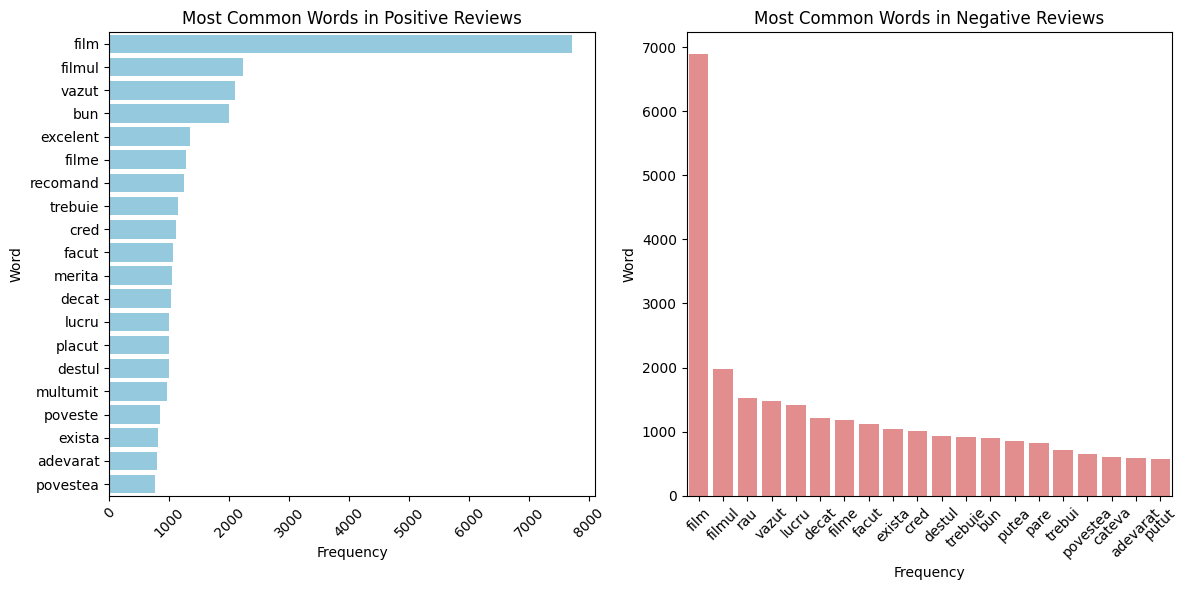

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

common_pos = pos_counter.most_common(20)
common_neg = neg_counter.most_common(20)

sns.barplot(x=[x[1] for x in common_pos], y=[x[0] for x in common_pos], ax=ax[0], color='skyblue')
ax[0].set_title('Most Common Words in Positive Reviews')
ax[0].set_xlabel('Frequency')
ax[0].set_ylabel('Word')
ax[0].tick_params(axis='x', labelrotation=45)

sns.barplot(x=[x[0] for x in common_neg], y=[x[1] for x in common_neg], ax=ax[1], color='lightcoral')
ax[1].set_title('Most Common Words in Negative Reviews')
ax[1].set_xlabel('Frequency')
ax[1].set_ylabel('Word')
ax[1].tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()

In [21]:
pos_counter = Counter()
neg_counter = Counter()

for text in test_loader[test_loader['label'] == 1]['text'].fillna(''):
    words = text.split()

    clean_words = []
    for word in words:
        if word.lower() not in stop_words_filtered and word.isalpha():
            clean_words.append(word)

    pos_counter.update(clean_words)

for text in test_loader[test_loader['label'] == 0]['text'].fillna(''):
    words = text.split()

    clean_words = []
    for word in words:
        if word.lower() not in stop_words_filtered and word.isalpha():
            clean_words.append(word)

    neg_counter.update(clean_words)

print(pos_counter.most_common(10))
print(neg_counter.most_common(10))

[('film', 6608), ('filmul', 1824), ('vazut', 1613), ('filme', 1072), ('bun', 1058), ('trebuie', 1030), ('lucru', 1009), ('cred', 905), ('decat', 880), ('facut', 877)]
[('film', 6341), ('filmul', 1551), ('rau', 1425), ('lucru', 1335), ('vazut', 1219), ('filme', 1006), ('decat', 999), ('exista', 985), ('facut', 969), ('trebuie', 854)]


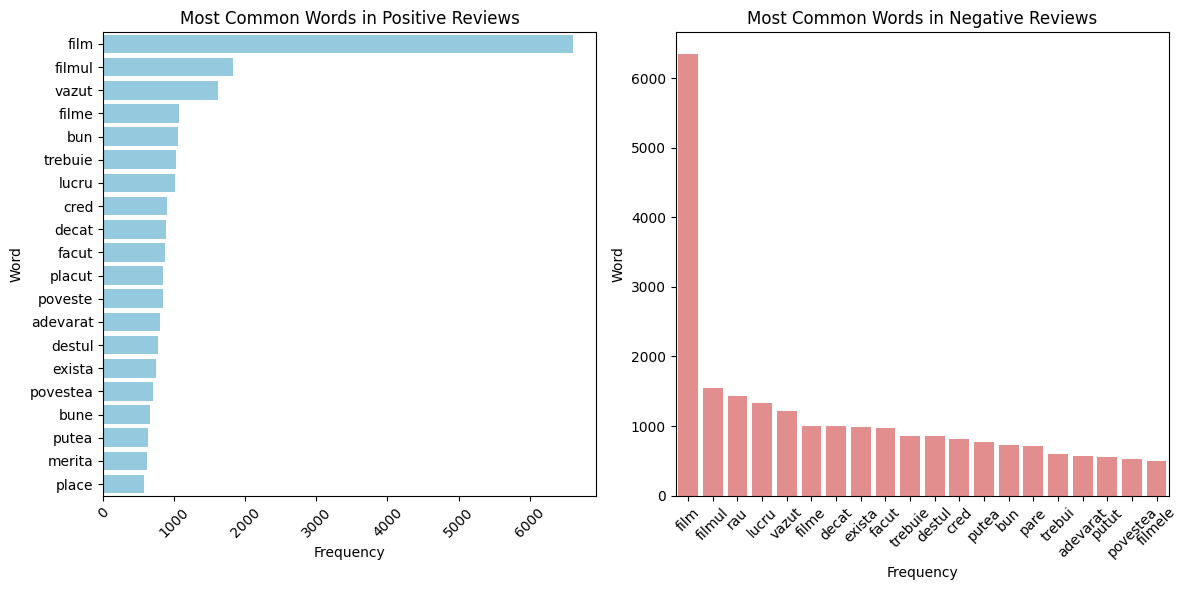

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

common_pos = pos_counter.most_common(20)
common_neg = neg_counter.most_common(20)

sns.barplot(x=[x[1] for x in common_pos], y=[x[0] for x in common_pos], ax=ax[0], color='skyblue')
ax[0].set_title('Most Common Words in Positive Reviews')
ax[0].set_xlabel('Frequency')
ax[0].set_ylabel('Word')
ax[0].tick_params(axis='x', labelrotation=45)

sns.barplot(x=[x[0] for x in common_neg], y=[x[1] for x in common_neg], ax=ax[1], color='lightcoral')
ax[1].set_title('Most Common Words in Negative Reviews')
ax[1].set_xlabel('Frequency')
ax[1].set_ylabel('Word')
ax[1].tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()

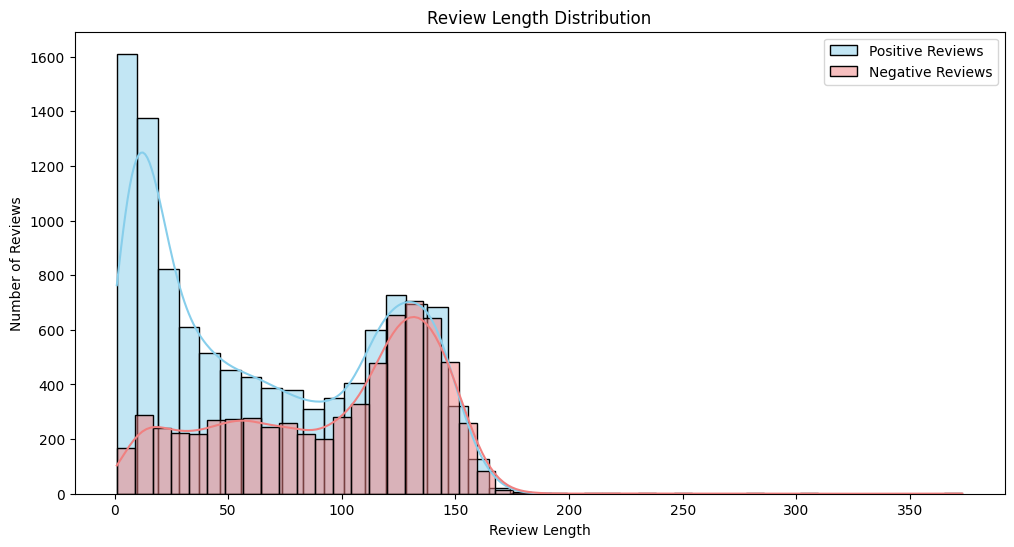

In [23]:
pos_counter = Counter()
neg_counter = Counter()

for text in train_loader[train_loader['label'] == 1]['text'].fillna(''):
  length = len(text.split())
  pos_counter.update([length])

for text in train_loader[train_loader['label'] == 0]['text'].fillna(''):
  length = len(text.split())
  neg_counter.update([length])

pos_lengths = list(pos_counter.elements())
neg_lengths = list(neg_counter.elements())

plt.figure(figsize=(12, 6))

sns.histplot(pos_lengths, color='skyblue', label='Positive Reviews', kde=True)
sns.histplot(neg_lengths, color='lightcoral', label='Negative Reviews', kde=True)

plt.title('Review Length Distribution')
plt.xlabel('Review Length')
plt.ylabel('Number of Reviews')
plt.legend()

plt.show()

## 2. Tokenize and Embedding

In [24]:
nltk.download('punkt_tab')

clean_pattern = re.compile(r"[^a-z\s]")

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = remove_diacritics(text)
    text = clean_pattern.sub(" ", text)

    tokens = word_tokenize(text)
    copy_tokens = []

    for token in tokens:
        if token not in stop_words_filtered and len(token) > 1:
            copy_tokens.append(token)

    tokens = copy_tokens

    return " ".join(tokens)


def clean_dataset(dataset, text_field, new_text_field_name):
    df = dataset.copy()

    df[new_text_field_name] = df[text_field].apply(clean_text)

    df = df[df[new_text_field_name].str.strip() != '']

    return df.reset_index(drop=True)

train_loader = clean_dataset(train_loader, 'text', 'text_clean')
test_loader = clean_dataset(test_loader, 'text', 'text_clean')

print(train_loader[['text', 'text_clean']].head())

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


                                                text  \
0  acest document mi-a deschis cu adevarat ochii ...   
1  tine mancarea rece. ce altceva ii mai trebuie?...   
2                                excelent\nrecomand!   
3  ca un rocker imbatranit, acest film mentioneaz...   
4  ei bine, a facut o groaza veche si foarte intu...   

                                          text_clean  
0  document deschis adevarat ochii oamenii afara ...  
1  mancarea rece trebuie frigiderul an utilizare ...  
2                                  excelent recomand  
3  rocker imbatranit film mentioneaza heep and qu...  
4  facut groaza veche intunecata casa setare incl...  


In [25]:
nlp = spacy.load("ro_core_news_sm", disable=["ner", "parser", "tagger", "lemmatizer"])

def tokenize(text_field):
    tokenized_list = []
    for doc in nlp.pipe(text_field.astype(str), batch_size=1000):
      tokens = []
      for token in doc:
        if not token.is_space:
          tokens.append(token.text)
      tokenized_list.append(tokens)
    return tokenized_list

def text_to_indices(tokens, max_len=100):
    indices = []
    for token in tokens:
        indices.append(vocab.get(token, vocab["<UNK>"]))

    if len(indices) > max_len:
        indices = indices[:max_len]

    indices += [0] * (max_len - len(indices))

    return indices

In [26]:
train_loader['tokens'] = tokenize(train_loader['text_clean'])
test_loader['tokens'] = tokenize(test_loader['text_clean'])
print(train_loader[['text_clean', 'tokens']].head())

all_words = []
for tokens_list in train_loader['tokens']:
    all_words.extend(tokens_list)
for tokens_list in test_loader['tokens']:
    all_words.extend(tokens_list)

word_counts = Counter(all_words)
vocab = {"<PAD>": 0, "<UNK>": 1}

for word, count in word_counts.items():
    if count >= 2:
        vocab[word] = len(vocab)

train_loader['indices'] = train_loader['tokens'].apply(lambda x: text_to_indices(x, max_len=100))
test_loader['indices'] = test_loader['tokens'].apply(lambda x: text_to_indices(x, max_len=100))

print(train_loader[['tokens', 'indices']].head())

                                          text_clean  \
0  document deschis adevarat ochii oamenii afara ...   
1  mancarea rece trebuie frigiderul an utilizare ...   
2                                  excelent recomand   
3  rocker imbatranit film mentioneaza heep and qu...   
4  facut groaza veche intunecata casa setare incl...   

                                              tokens  
0  [document, deschis, adevarat, ochii, oamenii, ...  
1  [mancarea, rece, trebuie, frigiderul, an, util...  
2                               [excelent, recomand]  
3  [rocker, imbatranit, film, mentioneaza, heep, ...  
4  [facut, groaza, veche, intunecata, casa, setar...  
                                              tokens  \
0  [document, deschis, adevarat, ochii, oamenii, ...   
1  [mancarea, rece, trebuie, frigiderul, an, util...   
2                               [excelent, recomand]   
3  [rocker, imbatranit, film, mentioneaza, heep, ...   
4  [facut, groaza, veche, intunecata, casa, setar... 

In [27]:
!wget https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.ro.300.vec.gz
!gunzip cc.ro.300.vec.gz

--2026-01-16 21:43:51--  https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.ro.300.vec.gz
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 13.249.182.81, 13.249.182.39, 13.249.182.62, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|13.249.182.81|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1233659733 (1.1G) [binary/octet-stream]
Saving to: ‘cc.ro.300.vec.gz’

cc.ro.300.vec.gz    100%[===================>]   1.15G   135MB/s    in 6.2s    

2026-01-16 21:43:58 (190 MB/s) - ‘cc.ro.300.vec.gz’ saved [1233659733/1233659733]



In [28]:
file_path = 'data_fasttext.txt'

with open(file_path, 'w', encoding='utf-8') as f:
    for index, row in train_loader.iterrows():
        text = str(row['text_clean']).replace('\n', ' ')
        label = row['label']
        f.write(f"__label__{label} {text}\n")

TRAIN_FILEPATH = file_path

In [29]:
import fasttext
ft_model = fasttext.train_supervised(input=TRAIN_FILEPATH, lr=1.0, epoch=100, wordNgrams=2, bucket=200000, dim=300, loss='hs', pretrainedVectors="cc.ro.300.vec")

def create_embedding_matrix(vocab, trained_model, embedding_dim=300):
    matrix = np.random.normal(size=(len(vocab), embedding_dim))
    found = 0

    for word, idx in vocab.items():
        if idx == 0:
            continue
        matrix[idx] = trained_model.get_word_vector(word)
        found += 1

    return torch.tensor(matrix, dtype=torch.float32)

embedding_weights = create_embedding_matrix(vocab, ft_model)

embedding_layer = nn.Embedding.from_pretrained(embedding_weights, padding_idx=0, freeze=True)

In [30]:
X_train = torch.tensor(list(train_loader['indices'].values), dtype=torch.long)
X_test = torch.tensor(list(test_loader['indices'].values), dtype=torch.long)

y_train = torch.tensor(list(train_loader['label'].values), dtype=torch.float32)
y_test = torch.tensor(list(test_loader['label'].values), dtype=torch.float32)

print(f"Dimensiune Input Train: {X_train.shape}")
print(f"Dimensiune Label Train: {y_train.shape}")

Dimensiune Input Train: torch.Size([17642, 100])
Dimensiune Label Train: torch.Size([17642])


In [31]:
X_train_final, X_val, y_train_final, y_val = train_test_split(X_train.numpy(), y_train.numpy(), test_size=0.2, random_state=42, stratify=y_train.numpy())

X_train_final = torch.tensor(X_train_final, dtype=torch.long)
y_train_final = torch.tensor(y_train_final, dtype=torch.float32)

X_val = torch.tensor(X_val, dtype=torch.long)
y_val = torch.tensor(y_val, dtype=torch.float32)

print(f"Train Final: {X_train_final.shape}")
print(f"Validation:  {X_val.shape}")

Train Final: torch.Size([14113, 100])
Validation:  torch.Size([3529, 100])


In [32]:
BATCH_SIZE = 64

train_dataset = TensorDataset(X_train_final, y_train_final)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

train_loader_final = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader_final = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader_final = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=True)

In [33]:
def loopy_test_loader(dl):
    data_iter = iter(dl)

    while True:
        try:
            yield next(data_iter)
        except StopIteration:
            data_iter = iter(dl)
            yield next(data_iter)

In [34]:
from IPython import display

def plot_losses(loss_list, steps, ct):
    if ct % 1000 == 0:
        display.clear_output(wait=True)

    display.display(plt.gcf())
    plt.clf()
    plt.plot(steps, loss_list, c='b', label='Train Loss')
    plt.xlabel("Steps")
    plt.ylabel("Loss")
    plt.legend()

def get_num_params(model):
    num_params = 0
    for params in model.parameters():
        num_params += params.shape.numel()
    return num_params

def binary_accuracy(preds, y):
    rounded_preds = torch.round(torch.sigmoid(preds))
    correct = (rounded_preds == y).float()
    acc = correct.sum() / len(correct)
    return acc

def evaluate_final(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    total_acc = 0
    count = 0

    with torch.no_grad():
        for batch in loader:
            text = batch[0].to(device)
            labels = batch[1].to(device)

            predictions = model(text).squeeze(1)

            loss = criterion(predictions, labels)
            acc = binary_accuracy(predictions, labels)

            total_loss += loss.item()
            total_acc += acc.item()
            count += 1

    return total_loss / count, total_acc / count

In [35]:
import torch.nn.functional as F

class LSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers, num_classes, dropout, embedding_weights, bidirectional):
        super(LSTM, self).__init__()

        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.bidirectional = bidirectional

        if embedding_weights is not None:
            self.embedding = nn.Embedding.from_pretrained(embedding_weights, padding_idx=0, freeze=False)
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers,
                            batch_first=True,
                            dropout=dropout if num_layers > 1 else 0,
                            bidirectional=bidirectional)

        self.dropout_layer = nn.Dropout(dropout)

        if bidirectional:
            fc_in_dim = hidden_dim * 2
        else:
            fc_in_dim = hidden_dim

        self.fc = nn.Linear(fc_in_dim, num_classes)

    def forward(self, text):
        embedded = self.embedding(text)

        lstm_out, (hidden, cell) = self.lstm(embedded)

        last_step_output = lstm_out[:, -1, :]

        out = self.dropout_layer(last_step_output)
        out = self.fc(out)
        return out

In [36]:
class RNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers, num_classes, dropout, embedding_weights, bidirectional):
        super(RNN, self).__init__()

        self.bidirectional = bidirectional
        self.num_layers = num_layers
        self.hidden_dim = hidden_dim

        if embedding_weights is not None:
            self.embedding = nn.Embedding.from_pretrained(embedding_weights, padding_idx=0, freeze=False)
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        self.rnn = nn.RNN(embedding_dim, hidden_dim, num_layers, batch_first=True, bidirectional=bidirectional, dropout=dropout if num_layers > 1 else 0)

        if bidirectional:
            fc_input_dim = hidden_dim * 2
        else:
            fc_input_dim = hidden_dim

        self.fc = nn.Linear(fc_input_dim, num_classes)
        self.dropout = nn.Dropout(dropout)

    def forward(self, text):
        embedded = self.embedding(text)
        embedded = self.dropout(embedded)

        output, hidden = self.rnn(embedded)

        if self.bidirectional:
            hidden_forward = hidden[-2, :, :]
            hidden_backward = hidden[-1, :, :]
            pooled = torch.cat((hidden_forward, hidden_backward), dim=1)
        else:
            pooled = hidden[-1, :, :]

        pooled = self.dropout(pooled)
        return self.fc(pooled)

In [37]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython import display

EPOCHS_GRID = 5
REPORT_TRAIN_EVERY = 50
REPORT_TEST_EVERY = 50

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

criterion = nn.CrossEntropyLoss().to(device)

def train_engine(net, train_data_loader, test_data_loader, optimizer, criterion, scheduler=None, num_epochs=35, name="Experiment", device='cpu'):

    history = {
        'train_loss': [], 'train_acc': [], 'train_steps': [],
        'val_loss': [], 'val_acc': [], 'val_steps': []
    }

    train_iter = 0
    running_loss = 0.0
    running_acc = 0.0

    plt.figure(figsize=(12, 5))

    net.train()

    for epoch in range(num_epochs):
        for i, batch in enumerate(train_data_loader, 0):

            inputs = batch[0].to(device)
            labels = batch[1].to(device)

            optimizer.zero_grad()
            outputs = net(inputs).squeeze(1)
            loss = criterion(outputs, labels)
            loss.backward()

            nn.utils.clip_grad_norm_(net.parameters(), max_norm=5)

            optimizer.step()

            running_loss += loss.item()
            running_acc += binary_accuracy(outputs, labels).item()

            if train_iter % REPORT_TRAIN_EVERY == REPORT_TRAIN_EVERY - 1:
                train_loss = running_loss / REPORT_TRAIN_EVERY
                train_acc = running_acc / REPORT_TRAIN_EVERY

                print(f'[{name}] [Ep: {epoch+1}, Step: {train_iter}] Train Loss: {train_loss:.5f}, Acc: {train_acc*100:.2f}%')

                history['train_loss'].append(train_loss)
                history['train_acc'].append(train_acc)
                history['train_steps'].append(train_iter)

                running_loss = 0.0
                running_acc = 0.0

            if train_iter % REPORT_TEST_EVERY == 0:
                net.eval()
                val_loss_accum = 0.0
                val_acc_accum = 0.0
                total_val_batches = 0

                with torch.no_grad():
                    for v_inputs, v_labels in test_data_loader:
                        v_inputs = v_inputs.to(device)
                        v_labels = v_labels.to(device)

                        v_outputs = net(v_inputs).squeeze(1)

                        val_loss_accum += criterion(v_outputs, v_labels).item()
                        val_acc_accum += binary_accuracy(v_outputs, v_labels).item()
                        total_val_batches += 1

                    avg_val_loss = val_loss_accum / total_val_batches
                    avg_val_acc = val_acc_accum / total_val_batches

                    print(f'>>> [{name} Val] Loss: {avg_val_loss:.5f}, Acc: {avg_val_acc*100:.2f}%')

                    history['val_loss'].append(avg_val_loss)
                    history['val_acc'].append(avg_val_acc)
                    history['val_steps'].append(train_iter)

                net.train()

            train_iter += 1

        if scheduler is not None:
            scheduler.step()

    print(f"Finished: {name}")
    plt.close()
    return history


Starting: LSTM_Fast_Learning
>>> [LSTM_Fast_Learning Val] Loss: 160.56932, Acc: 61.06%
[LSTM_Fast_Learning] [Ep: 1, Step: 49] Train Loss: 162.28629, Acc: 52.66%
>>> [LSTM_Fast_Learning Val] Loss: 160.56874, Acc: 61.06%
[LSTM_Fast_Learning] [Ep: 1, Step: 99] Train Loss: 165.81758, Acc: 61.72%
>>> [LSTM_Fast_Learning Val] Loss: 160.46099, Acc: 61.63%
[LSTM_Fast_Learning] [Ep: 1, Step: 149] Train Loss: 163.71499, Acc: 61.47%
>>> [LSTM_Fast_Learning Val] Loss: 160.46133, Acc: 61.63%
[LSTM_Fast_Learning] [Ep: 1, Step: 199] Train Loss: 163.59487, Acc: 61.47%
>>> [LSTM_Fast_Learning Val] Loss: 160.53002, Acc: 61.29%
[LSTM_Fast_Learning] [Ep: 2, Step: 249] Train Loss: 157.82075, Acc: 59.99%
>>> [LSTM_Fast_Learning Val] Loss: 160.53116, Acc: 61.29%
[LSTM_Fast_Learning] [Ep: 2, Step: 299] Train Loss: 163.09991, Acc: 61.03%
>>> [LSTM_Fast_Learning Val] Loss: 160.60283, Acc: 60.95%
[LSTM_Fast_Learning] [Ep: 2, Step: 349] Train Loss: 161.72931, Acc: 58.28%
>>> [LSTM_Fast_Learning Val] Loss: 160.49

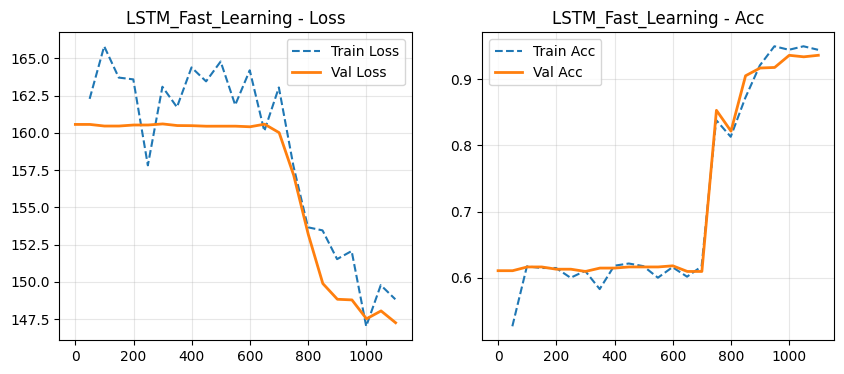


Starting: LSTM_Balanced
>>> [LSTM_Balanced Val] Loss: 160.63979, Acc: 60.72%
[LSTM_Balanced] [Ep: 1, Step: 49] Train Loss: 164.80686, Acc: 42.41%
>>> [LSTM_Balanced Val] Loss: 160.60994, Acc: 39.11%
[LSTM_Balanced] [Ep: 1, Step: 99] Train Loss: 164.10257, Acc: 41.03%
>>> [LSTM_Balanced Val] Loss: 160.53934, Acc: 38.77%
[LSTM_Balanced] [Ep: 1, Step: 149] Train Loss: 164.22753, Acc: 38.81%
>>> [LSTM_Balanced Val] Loss: 160.53964, Acc: 38.77%
[LSTM_Balanced] [Ep: 1, Step: 199] Train Loss: 159.32082, Acc: 44.03%
>>> [LSTM_Balanced Val] Loss: 160.49824, Acc: 61.46%
[LSTM_Balanced] [Ep: 2, Step: 249] Train Loss: 162.80554, Acc: 47.38%
>>> [LSTM_Balanced Val] Loss: 160.50045, Acc: 38.60%
[LSTM_Balanced] [Ep: 2, Step: 299] Train Loss: 165.39020, Acc: 43.75%
>>> [LSTM_Balanced Val] Loss: 160.53496, Acc: 38.77%
[LSTM_Balanced] [Ep: 2, Step: 349] Train Loss: 162.17837, Acc: 50.03%
>>> [LSTM_Balanced Val] Loss: 160.49856, Acc: 61.46%
[LSTM_Balanced] [Ep: 2, Step: 399] Train Loss: 162.59928, Acc: 

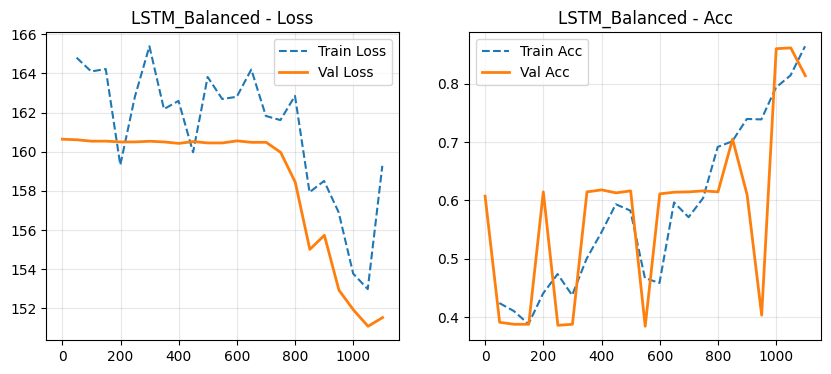


Starting: LSTM_Deep_Reg
>>> [LSTM_Deep_Reg Val] Loss: 160.50138, Acc: 38.60%
[LSTM_Deep_Reg] [Ep: 1, Step: 49] Train Loss: 164.90251, Acc: 47.94%
>>> [LSTM_Deep_Reg Val] Loss: 160.50025, Acc: 38.60%
[LSTM_Deep_Reg] [Ep: 1, Step: 99] Train Loss: 160.87833, Acc: 48.31%
>>> [LSTM_Deep_Reg Val] Loss: 160.56868, Acc: 61.12%
[LSTM_Deep_Reg] [Ep: 1, Step: 149] Train Loss: 164.73588, Acc: 60.88%
>>> [LSTM_Deep_Reg Val] Loss: 160.53158, Acc: 61.29%
[LSTM_Deep_Reg] [Ep: 1, Step: 199] Train Loss: 163.53881, Acc: 61.44%
>>> [LSTM_Deep_Reg Val] Loss: 160.53066, Acc: 61.29%
[LSTM_Deep_Reg] [Ep: 2, Step: 249] Train Loss: 162.17975, Acc: 61.49%
>>> [LSTM_Deep_Reg Val] Loss: 160.53138, Acc: 61.29%
[LSTM_Deep_Reg] [Ep: 2, Step: 299] Train Loss: 163.56141, Acc: 60.53%
>>> [LSTM_Deep_Reg Val] Loss: 160.53318, Acc: 61.29%
[LSTM_Deep_Reg] [Ep: 2, Step: 349] Train Loss: 165.71363, Acc: 58.72%
>>> [LSTM_Deep_Reg Val] Loss: 160.46312, Acc: 61.63%
[LSTM_Deep_Reg] [Ep: 2, Step: 399] Train Loss: 161.03702, Acc: 

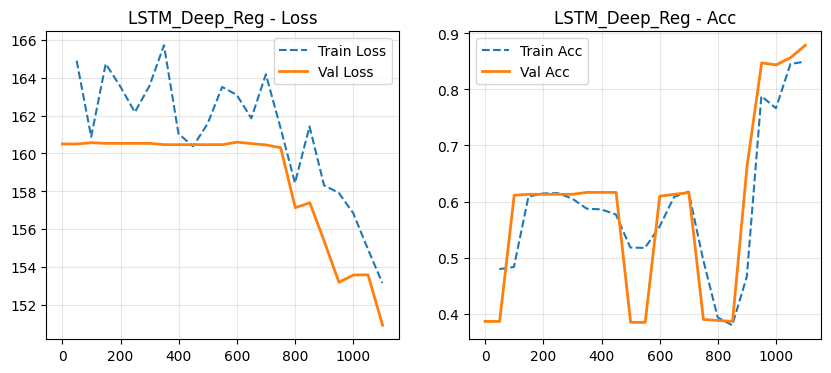


Starting: LSTM_Simple
>>> [LSTM_Simple Val] Loss: 160.53609, Acc: 38.77%
[LSTM_Simple] [Ep: 1, Step: 49] Train Loss: 165.26167, Acc: 51.62%
>>> [LSTM_Simple Val] Loss: 160.56963, Acc: 61.12%
[LSTM_Simple] [Ep: 1, Step: 99] Train Loss: 166.94289, Acc: 47.47%
>>> [LSTM_Simple Val] Loss: 160.53528, Acc: 38.77%
[LSTM_Simple] [Ep: 1, Step: 149] Train Loss: 160.05590, Acc: 49.53%
>>> [LSTM_Simple Val] Loss: 160.46356, Acc: 61.63%
[LSTM_Simple] [Ep: 1, Step: 199] Train Loss: 159.89532, Acc: 59.00%
>>> [LSTM_Simple Val] Loss: 160.46204, Acc: 61.63%
[LSTM_Simple] [Ep: 2, Step: 249] Train Loss: 163.53875, Acc: 61.80%
>>> [LSTM_Simple Val] Loss: 160.46126, Acc: 61.63%
[LSTM_Simple] [Ep: 2, Step: 299] Train Loss: 164.72735, Acc: 60.56%
>>> [LSTM_Simple Val] Loss: 160.49466, Acc: 61.46%
[LSTM_Simple] [Ep: 2, Step: 349] Train Loss: 161.55928, Acc: 58.72%
>>> [LSTM_Simple Val] Loss: 160.46071, Acc: 61.63%
[LSTM_Simple] [Ep: 2, Step: 399] Train Loss: 159.74410, Acc: 54.94%
>>> [LSTM_Simple Val] Loss:

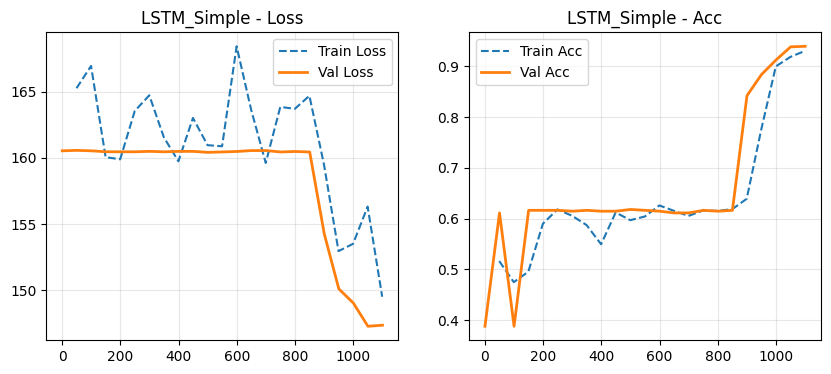

Best config found: {'name': 'LSTM_Fast_Learning', 'hidden_dim': 128, 'lr': 0.001, 'dropout': 0.2, 'weight_decay': 0.0}


,Model,Hidden,LR,Drop,WD,Best Val Loss,Best Val Acc
0,LSTM_Fast_Learning,128,0.0010,0.2,0.00000,147.2511,93.64%
1,LSTM_Balanced,256,0.0010,0.3,0.00001,151.0760,86.13%
2,LSTM_Deep_Reg,256,0.0005,0.4,0.00001,150.9222,87.89%
3,LSTM_Simple,64,0.0010,0.2,0.00000,147.2855,93.86%


In [ ]:
import copy
if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

EPOCHS_GRID = 6
criterion = nn.BCEWithLogitsLoss().to(device)

experiments_lstm = [
    {
        "name": "LSTM_Fast_Learning",
        "hidden_dim": 128,
        "lr": 1e-3,
        "dropout": 0.2,
        "weight_decay": 0.0
    },
    {
        "name": "LSTM_Balanced",
        "hidden_dim": 256,
        "lr": 1e-3,
        "dropout": 0.3,
        "weight_decay": 1e-5
    },
    {
        "name": "LSTM_Deep_Reg",
        "hidden_dim": 256,
        "lr": 5e-4,
        "dropout": 0.4,
        "weight_decay": 1e-5
    },
    {
        "name": "LSTM_Simple",
        "hidden_dim": 64,
        "lr": 1e-3,
        "dropout": 0.2,
        "weight_decay": 0.0
    }
]

results_table = []
best_valid_loss = float('inf')
best_config = {}
best_hist = None

for exp in experiments_lstm:
    print(f"\n{'='*60}")
    print(f"Starting: {exp['name']}")
    print(f"{'='*60}")

    net = LSTM(vocab_size=len(vocab), embedding_dim=300, hidden_dim=exp['hidden_dim'], num_layers=2,
               num_classes=1,dropout=exp['dropout'], embedding_weights=embedding_weights, bidirectional=True).to(device)

    optimizer = optim.Adam(net.parameters(), lr=exp['lr'], weight_decay=exp['weight_decay'])

    hist = train_engine(net=net, train_data_loader=train_loader_final, test_data_loader=val_loader_final,
                        optimizer=optimizer, criterion=criterion, num_epochs=5, name=exp['name'], device=device)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.plot(hist['train_steps'], hist['train_loss'], label='Train Loss', linestyle='--')
    plt.plot(hist['val_steps'], hist['val_loss'], label='Val Loss', linewidth=2)
    plt.title(f"{exp['name']} - Loss")
    plt.legend(); plt.grid(True, alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(hist['train_steps'], hist['train_acc'], label='Train Acc', linestyle='--')
    plt.plot(hist['val_steps'], hist['val_acc'], label='Val Acc', linewidth=2)
    plt.title(f"{exp['name']} - Acc")
    plt.legend(); plt.grid(True, alpha=0.3)
    plt.show()

    best_val_loss_in_run = min(hist['val_loss'])
    best_idx = hist['val_loss'].index(best_val_loss_in_run)
    val_acc_at_best_loss = hist['val_acc'][best_idx]

    results_table.append({
        "Model": exp['name'],
        "Hidden": exp['hidden_dim'],
        "LR": exp['lr'],
        "Drop": exp['dropout'],
        "WD": exp['weight_decay'],
        "Best Val Loss": f"{best_val_loss_in_run:.4f}",
        "Best Val Acc": f"{val_acc_at_best_loss*100:.2f}%"
    })

    if best_val_loss_in_run < best_valid_loss:
        best_valid_loss = best_val_loss_in_run
        best_config = exp.copy()
        best_hist = copy.deepcopy(hist)

print("=" * 60)
print(f"Best config found: {best_config}")

if results_table:
    df_results = pd.DataFrame(results_table)
    try:
        from IPython.display import display
        display(df_results)
    except:
        print(df_results)


Starting: LSTM_Fast_Learning
>>> [LSTM_Fast_Learning Val] Loss: 160.56932, Acc: 61.06%
[LSTM_Fast_Learning] [Ep: 1, Step: 49] Train Loss: 162.28629, Acc: 52.66%
>>> [LSTM_Fast_Learning Val] Loss: 160.56874, Acc: 61.06%
[LSTM_Fast_Learning] [Ep: 1, Step: 99] Train Loss: 165.81758, Acc: 61.72%
>>> [LSTM_Fast_Learning Val] Loss: 160.46099, Acc: 61.63%
[LSTM_Fast_Learning] [Ep: 1, Step: 149] Train Loss: 163.71499, Acc: 61.47%
>>> [LSTM_Fast_Learning Val] Loss: 160.46133, Acc: 61.63%
[LSTM_Fast_Learning] [Ep: 1, Step: 199] Train Loss: 163.59487, Acc: 61.47%
>>> [LSTM_Fast_Learning Val] Loss: 160.53002, Acc: 61.29%
[LSTM_Fast_Learning] [Ep: 2, Step: 249] Train Loss: 157.82075, Acc: 59.99%
>>> [LSTM_Fast_Learning Val] Loss: 160.53116, Acc: 61.29%
[LSTM_Fast_Learning] [Ep: 2, Step: 299] Train Loss: 163.09991, Acc: 61.03%
>>> [LSTM_Fast_Learning Val] Loss: 160.60283, Acc: 60.95%
[LSTM_Fast_Learning] [Ep: 2, Step: 349] Train Loss: 161.72931, Acc: 58.28%
>>> [LSTM_Fast_Learning Val] Loss: 160.49

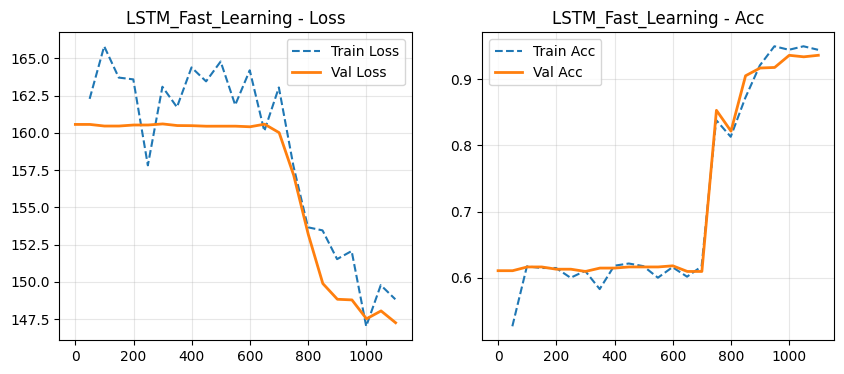


Starting: LSTM_Balanced
>>> [LSTM_Balanced Val] Loss: 160.63979, Acc: 60.72%
[LSTM_Balanced] [Ep: 1, Step: 49] Train Loss: 164.80686, Acc: 42.41%
>>> [LSTM_Balanced Val] Loss: 160.60994, Acc: 39.11%
[LSTM_Balanced] [Ep: 1, Step: 99] Train Loss: 164.10257, Acc: 41.03%
>>> [LSTM_Balanced Val] Loss: 160.53934, Acc: 38.77%
[LSTM_Balanced] [Ep: 1, Step: 149] Train Loss: 164.22753, Acc: 38.81%
>>> [LSTM_Balanced Val] Loss: 160.53964, Acc: 38.77%
[LSTM_Balanced] [Ep: 1, Step: 199] Train Loss: 159.32082, Acc: 44.03%
>>> [LSTM_Balanced Val] Loss: 160.49824, Acc: 61.46%
[LSTM_Balanced] [Ep: 2, Step: 249] Train Loss: 162.80554, Acc: 47.38%
>>> [LSTM_Balanced Val] Loss: 160.50045, Acc: 38.60%
[LSTM_Balanced] [Ep: 2, Step: 299] Train Loss: 165.39020, Acc: 43.75%
>>> [LSTM_Balanced Val] Loss: 160.53496, Acc: 38.77%
[LSTM_Balanced] [Ep: 2, Step: 349] Train Loss: 162.17837, Acc: 50.03%
>>> [LSTM_Balanced Val] Loss: 160.49856, Acc: 61.46%
[LSTM_Balanced] [Ep: 2, Step: 399] Train Loss: 162.59928, Acc: 

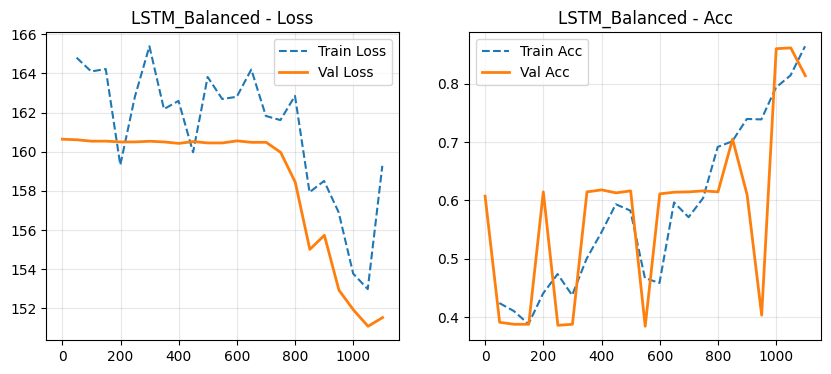


Starting: LSTM_Deep_Reg
>>> [LSTM_Deep_Reg Val] Loss: 160.50138, Acc: 38.60%
[LSTM_Deep_Reg] [Ep: 1, Step: 49] Train Loss: 164.90251, Acc: 47.94%
>>> [LSTM_Deep_Reg Val] Loss: 160.50025, Acc: 38.60%
[LSTM_Deep_Reg] [Ep: 1, Step: 99] Train Loss: 160.87833, Acc: 48.31%
>>> [LSTM_Deep_Reg Val] Loss: 160.56868, Acc: 61.12%
[LSTM_Deep_Reg] [Ep: 1, Step: 149] Train Loss: 164.73588, Acc: 60.88%
>>> [LSTM_Deep_Reg Val] Loss: 160.53158, Acc: 61.29%
[LSTM_Deep_Reg] [Ep: 1, Step: 199] Train Loss: 163.53881, Acc: 61.44%
>>> [LSTM_Deep_Reg Val] Loss: 160.53066, Acc: 61.29%
[LSTM_Deep_Reg] [Ep: 2, Step: 249] Train Loss: 162.17975, Acc: 61.49%
>>> [LSTM_Deep_Reg Val] Loss: 160.53138, Acc: 61.29%
[LSTM_Deep_Reg] [Ep: 2, Step: 299] Train Loss: 163.56141, Acc: 60.53%
>>> [LSTM_Deep_Reg Val] Loss: 160.53318, Acc: 61.29%
[LSTM_Deep_Reg] [Ep: 2, Step: 349] Train Loss: 165.71363, Acc: 58.72%
>>> [LSTM_Deep_Reg Val] Loss: 160.46312, Acc: 61.63%
[LSTM_Deep_Reg] [Ep: 2, Step: 399] Train Loss: 161.03702, Acc: 

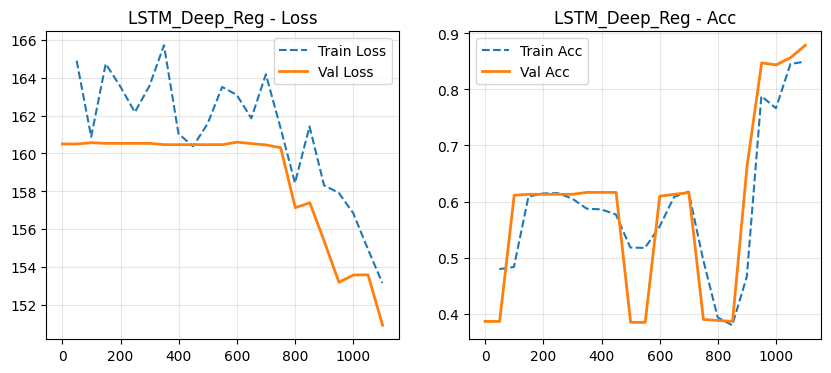


Starting: LSTM_Simple
>>> [LSTM_Simple Val] Loss: 160.53609, Acc: 38.77%
[LSTM_Simple] [Ep: 1, Step: 49] Train Loss: 165.26167, Acc: 51.62%
>>> [LSTM_Simple Val] Loss: 160.56963, Acc: 61.12%
[LSTM_Simple] [Ep: 1, Step: 99] Train Loss: 166.94289, Acc: 47.47%
>>> [LSTM_Simple Val] Loss: 160.53528, Acc: 38.77%
[LSTM_Simple] [Ep: 1, Step: 149] Train Loss: 160.05590, Acc: 49.53%
>>> [LSTM_Simple Val] Loss: 160.46356, Acc: 61.63%
[LSTM_Simple] [Ep: 1, Step: 199] Train Loss: 159.89532, Acc: 59.00%
>>> [LSTM_Simple Val] Loss: 160.46204, Acc: 61.63%
[LSTM_Simple] [Ep: 2, Step: 249] Train Loss: 163.53875, Acc: 61.80%
>>> [LSTM_Simple Val] Loss: 160.46126, Acc: 61.63%
[LSTM_Simple] [Ep: 2, Step: 299] Train Loss: 164.72735, Acc: 60.56%
>>> [LSTM_Simple Val] Loss: 160.49466, Acc: 61.46%
[LSTM_Simple] [Ep: 2, Step: 349] Train Loss: 161.55928, Acc: 58.72%
>>> [LSTM_Simple Val] Loss: 160.46071, Acc: 61.63%
[LSTM_Simple] [Ep: 2, Step: 399] Train Loss: 159.74410, Acc: 54.94%
>>> [LSTM_Simple Val] Loss:

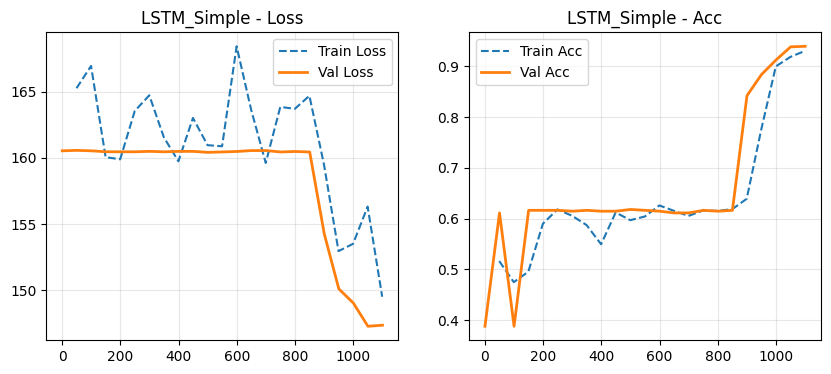

Best config found: {'name': 'LSTM_Fast_Learning', 'hidden_dim': 128, 'lr': 0.001, 'dropout': 0.2, 'weight_decay': 0.0}


,Model,Hidden,LR,Drop,WD,Best Val Loss,Best Val Acc
0,LSTM_Fast_Learning,128,0.0010,0.2,0.00000,147.2511,93.64%
1,LSTM_Balanced,256,0.0010,0.3,0.00001,151.0760,86.13%
2,LSTM_Deep_Reg,256,0.0005,0.4,0.00001,150.9222,87.89%
3,LSTM_Simple,64,0.0010,0.2,0.00000,147.2855,93.86%


In [38]:
import copy
if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

EPOCHS_GRID = 6
criterion = nn.BCEWithLogitsLoss().to(device)

experiments_lstm = [
    {
        "name": "LSTM_Fast_Learning",
        "hidden_dim": 128,
        "lr": 1e-3,
        "dropout": 0.2,
        "weight_decay": 0.0
    },
    {
        "name": "LSTM_Balanced",
        "hidden_dim": 256,
        "lr": 1e-3,
        "dropout": 0.3,
        "weight_decay": 1e-5
    },
    {
        "name": "LSTM_Deep_Reg",
        "hidden_dim": 256,
        "lr": 5e-4,
        "dropout": 0.4,
        "weight_decay": 1e-5
    },
    {
        "name": "LSTM_Simple",
        "hidden_dim": 64,
        "lr": 1e-3,
        "dropout": 0.2,
        "weight_decay": 0.0
    }
]

results_table = []
best_valid_loss = float('inf')
best_config = {}
best_hist = None

for exp in experiments_lstm:
    print(f"\n{'='*60}")
    print(f"Starting: {exp['name']}")
    print(f"{'='*60}")

    net = LSTM(vocab_size=len(vocab), embedding_dim=300, hidden_dim=exp['hidden_dim'], num_layers=2,
               num_classes=1,dropout=exp['dropout'], embedding_weights=embedding_weights, bidirectional=True).to(device)

    optimizer = optim.Adam(net.parameters(), lr=exp['lr'], weight_decay=exp['weight_decay'])

    hist = train_engine(net=net, train_data_loader=train_loader_final, test_data_loader=val_loader_final,
                        optimizer=optimizer, criterion=criterion, num_epochs=5, name=exp['name'], device=device)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.plot(hist['train_steps'], hist['train_loss'], label='Train Loss', linestyle='--')
    plt.plot(hist['val_steps'], hist['val_loss'], label='Val Loss', linewidth=2)
    plt.title(f"{exp['name']} - Loss")
    plt.legend(); plt.grid(True, alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(hist['train_steps'], hist['train_acc'], label='Train Acc', linestyle='--')
    plt.plot(hist['val_steps'], hist['val_acc'], label='Val Acc', linewidth=2)
    plt.title(f"{exp['name']} - Acc")
    plt.legend(); plt.grid(True, alpha=0.3)
    plt.show()

    best_val_loss_in_run = min(hist['val_loss'])
    best_idx = hist['val_loss'].index(best_val_loss_in_run)
    val_acc_at_best_loss = hist['val_acc'][best_idx]

    results_table.append({
        "Model": exp['name'],
        "Hidden": exp['hidden_dim'],
        "LR": exp['lr'],
        "Drop": exp['dropout'],
        "WD": exp['weight_decay'],
        "Best Val Loss": f"{best_val_loss_in_run:.4f}",
        "Best Val Acc": f"{val_acc_at_best_loss*100:.2f}%"
    })

    if best_val_loss_in_run < best_valid_loss:
        best_valid_loss = best_val_loss_in_run
        best_config = exp.copy()
        best_hist = copy.deepcopy(hist)

print("=" * 60)
print(f"Best config found: {best_config}")

if results_table:
    df_results = pd.DataFrame(results_table)
    try:
        from IPython.display import display
        display(df_results)
    except:
        print(df_results)

>>> [Final_Run_on_Test Val] Loss: 149.29596, Acc: 43.90%
[Final_Run_on_Test] [Ep: 1, Step: 49] Train Loss: 165.16642, Acc: 61.56%
>>> [Final_Run_on_Test Val] Loss: 149.28980, Acc: 56.12%
[Final_Run_on_Test] [Ep: 1, Step: 99] Train Loss: 160.73581, Acc: 59.03%
>>> [Final_Run_on_Test Val] Loss: 149.29439, Acc: 56.11%
[Final_Run_on_Test] [Ep: 1, Step: 149] Train Loss: 162.35991, Acc: 60.78%
>>> [Final_Run_on_Test Val] Loss: 149.29198, Acc: 56.12%
[Final_Run_on_Test] [Ep: 1, Step: 199] Train Loss: 162.01466, Acc: 60.84%
>>> [Final_Run_on_Test Val] Loss: 149.29336, Acc: 56.11%
[Final_Run_on_Test] [Ep: 2, Step: 249] Train Loss: 161.07141, Acc: 61.27%
>>> [Final_Run_on_Test Val] Loss: 149.29448, Acc: 56.11%
[Final_Run_on_Test] [Ep: 2, Step: 299] Train Loss: 165.09148, Acc: 62.06%
>>> [Final_Run_on_Test Val] Loss: 149.30088, Acc: 56.11%
[Final_Run_on_Test] [Ep: 2, Step: 349] Train Loss: 166.11153, Acc: 62.47%
>>> [Final_Run_on_Test Val] Loss: 148.21949, Acc: 56.14%
[Final_Run_on_Test] [Ep: 2, 

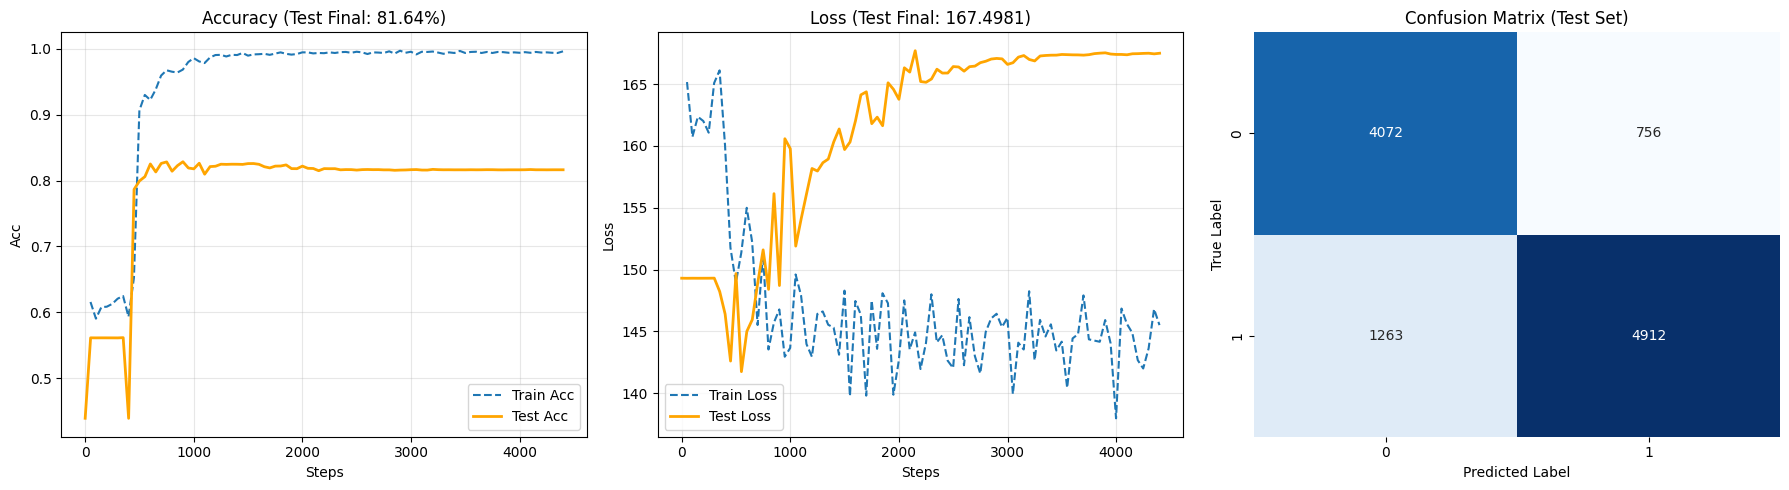


✅ GATA! Modelul final a obținut 81.64% pe setul de TEST.


In [39]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

final_lstm = LSTM(vocab_size=len(vocab), embedding_dim=300, hidden_dim=best_config['hidden_dim'], num_layers=2,
                  num_classes=1, dropout=best_config['dropout'], embedding_weights=embedding_weights, bidirectional=True).to(device)

optimizer = optim.Adam(final_lstm.parameters(), lr=best_config['lr'])
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

history = train_engine(net=final_lstm, train_data_loader=train_loader_final, test_data_loader=test_loader_final,
                       optimizer=optimizer, criterion=criterion, scheduler=scheduler, num_epochs=20, name="Final_Run_on_Test", device=device)

final_lstm.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in test_loader_final:
        inputs = batch[0].to(device)
        labels = batch[1].to(device)

        outputs = final_lstm(inputs).squeeze(1)
        preds = torch.round(torch.sigmoid(outputs))

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
final_test_acc = history['val_acc'][-1]
final_test_loss = history['val_loss'][-1]

plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.plot(history['train_steps'], history['train_acc'], label='Train Acc', linestyle='--')
plt.plot(history['val_steps'], history['val_acc'], label='Test Acc', linewidth=2, color='orange')
plt.title(f"Accuracy (Test Final: {final_test_acc*100:.2f}%)")
plt.xlabel("Steps")
plt.ylabel("Acc")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(history['train_steps'], history['train_loss'], label='Train Loss', linestyle='--')
plt.plot(history['val_steps'], history['val_loss'], label='Test Loss', linewidth=2, color='orange')
plt.title(f"Loss (Test Final: {final_test_loss:.4f})")
plt.xlabel("Steps")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (Test Set)')

plt.tight_layout()
plt.show()

print(f"\n✅ GATA! Modelul final a obținut {final_test_acc*100:.2f}% pe setul de TEST.")


Starting: RNN_Fast
>>> [RNN_Fast Val] Loss: 157.14772, Acc: 70.36%
[RNN_Fast] [Ep: 1, Step: 49] Train Loss: 158.52198, Acc: 85.28%
>>> [RNN_Fast Val] Loss: 148.79919, Acc: 88.64%
[RNN_Fast] [Ep: 1, Step: 99] Train Loss: 151.60582, Acc: 85.34%
>>> [RNN_Fast Val] Loss: 147.74068, Acc: 90.76%
[RNN_Fast] [Ep: 1, Step: 149] Train Loss: 157.33887, Acc: 90.25%
>>> [RNN_Fast Val] Loss: 148.07113, Acc: 92.44%
[RNN_Fast] [Ep: 1, Step: 199] Train Loss: 145.95659, Acc: 85.34%
>>> [RNN_Fast Val] Loss: 149.61629, Acc: 87.53%
[RNN_Fast] [Ep: 2, Step: 249] Train Loss: 149.97122, Acc: 92.60%
>>> [RNN_Fast Val] Loss: 147.90257, Acc: 92.10%
[RNN_Fast] [Ep: 2, Step: 299] Train Loss: 146.47769, Acc: 93.09%
>>> [RNN_Fast Val] Loss: 146.74437, Acc: 91.60%
[RNN_Fast] [Ep: 2, Step: 349] Train Loss: 150.04957, Acc: 92.69%
>>> [RNN_Fast Val] Loss: 148.81662, Acc: 93.11%
[RNN_Fast] [Ep: 2, Step: 399] Train Loss: 149.39137, Acc: 90.78%
>>> [RNN_Fast Val] Loss: 149.13881, Acc: 91.88%
[RNN_Fast] [Ep: 3, Step: 449] 

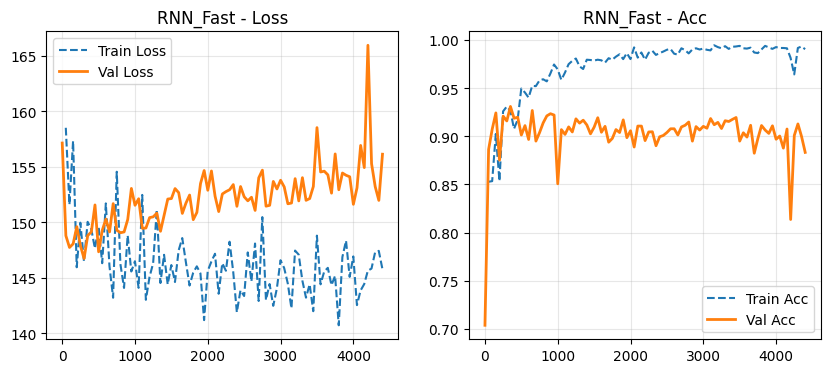


Starting: RNN_Balanced
>>> [RNN_Balanced Val] Loss: 159.63711, Acc: 75.07%
[RNN_Balanced] [Ep: 1, Step: 49] Train Loss: 155.03882, Acc: 74.53%
>>> [RNN_Balanced Val] Loss: 152.38900, Acc: 70.76%
[RNN_Balanced] [Ep: 1, Step: 99] Train Loss: 155.79926, Acc: 81.53%
>>> [RNN_Balanced Val] Loss: 148.27672, Acc: 89.87%
[RNN_Balanced] [Ep: 1, Step: 149] Train Loss: 151.22660, Acc: 86.50%
>>> [RNN_Balanced Val] Loss: 150.44470, Acc: 84.54%
[RNN_Balanced] [Ep: 1, Step: 199] Train Loss: 156.81753, Acc: 80.66%
>>> [RNN_Balanced Val] Loss: 151.24917, Acc: 89.03%
[RNN_Balanced] [Ep: 2, Step: 249] Train Loss: 154.38961, Acc: 86.38%
>>> [RNN_Balanced Val] Loss: 152.31433, Acc: 85.51%
[RNN_Balanced] [Ep: 2, Step: 299] Train Loss: 153.26225, Acc: 87.81%
>>> [RNN_Balanced Val] Loss: 154.06342, Acc: 82.61%
[RNN_Balanced] [Ep: 2, Step: 349] Train Loss: 154.13061, Acc: 86.34%
>>> [RNN_Balanced Val] Loss: 149.24875, Acc: 85.43%
[RNN_Balanced] [Ep: 2, Step: 399] Train Loss: 151.39571, Acc: 87.81%
>>> [RNN_B

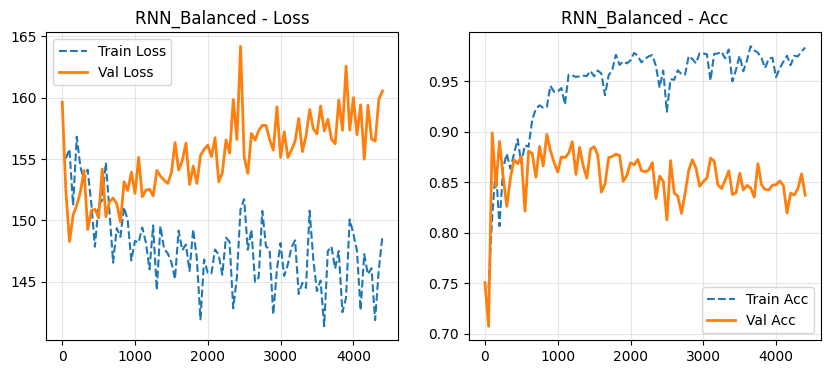


Starting: RNN_Conservative
>>> [RNN_Conservative Val] Loss: 159.13373, Acc: 69.86%
[RNN_Conservative] [Ep: 1, Step: 49] Train Loss: 157.58921, Acc: 80.94%
>>> [RNN_Conservative Val] Loss: 148.52358, Acc: 89.00%
[RNN_Conservative] [Ep: 1, Step: 99] Train Loss: 155.30499, Acc: 89.53%
>>> [RNN_Conservative Val] Loss: 150.56052, Acc: 89.50%
[RNN_Conservative] [Ep: 1, Step: 149] Train Loss: 154.57282, Acc: 87.75%
>>> [RNN_Conservative Val] Loss: 147.84438, Acc: 84.96%
[RNN_Conservative] [Ep: 1, Step: 199] Train Loss: 150.36459, Acc: 87.41%
>>> [RNN_Conservative Val] Loss: 148.09616, Acc: 88.67%
[RNN_Conservative] [Ep: 2, Step: 249] Train Loss: 148.84836, Acc: 89.41%
>>> [RNN_Conservative Val] Loss: 148.12006, Acc: 89.56%
[RNN_Conservative] [Ep: 2, Step: 299] Train Loss: 150.23620, Acc: 90.06%
>>> [RNN_Conservative Val] Loss: 148.15192, Acc: 90.45%
[RNN_Conservative] [Ep: 2, Step: 349] Train Loss: 149.31277, Acc: 90.19%
>>> [RNN_Conservative Val] Loss: 148.19903, Acc: 89.93%
[RNN_Conservati

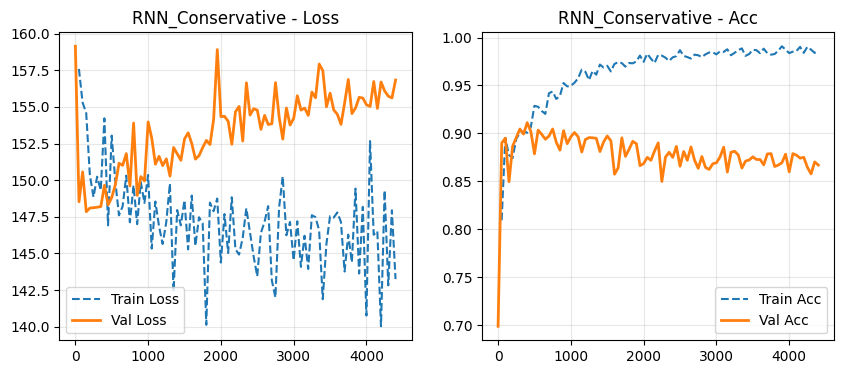


Starting: RNN_Small
>>> [RNN_Small Val] Loss: 158.43745, Acc: 67.46%
[RNN_Small] [Ep: 1, Step: 49] Train Loss: 155.61542, Acc: 82.25%
>>> [RNN_Small Val] Loss: 148.90136, Acc: 91.77%
[RNN_Small] [Ep: 1, Step: 99] Train Loss: 150.06104, Acc: 88.16%
>>> [RNN_Small Val] Loss: 147.44697, Acc: 90.04%
[RNN_Small] [Ep: 1, Step: 149] Train Loss: 151.59722, Acc: 89.31%
>>> [RNN_Small Val] Loss: 147.92562, Acc: 90.71%
[RNN_Small] [Ep: 1, Step: 199] Train Loss: 152.76048, Acc: 92.47%
>>> [RNN_Small Val] Loss: 147.01584, Acc: 92.18%
[RNN_Small] [Ep: 2, Step: 249] Train Loss: 149.91059, Acc: 93.07%
>>> [RNN_Small Val] Loss: 149.23165, Acc: 92.66%
[RNN_Small] [Ep: 2, Step: 299] Train Loss: 147.05908, Acc: 93.66%
>>> [RNN_Small Val] Loss: 147.90367, Acc: 92.24%
[RNN_Small] [Ep: 2, Step: 349] Train Loss: 148.52336, Acc: 92.66%
>>> [RNN_Small Val] Loss: 147.14895, Acc: 92.04%
[RNN_Small] [Ep: 2, Step: 399] Train Loss: 149.18274, Acc: 91.72%
>>> [RNN_Small Val] Loss: 147.96544, Acc: 88.13%
[RNN_Small] 

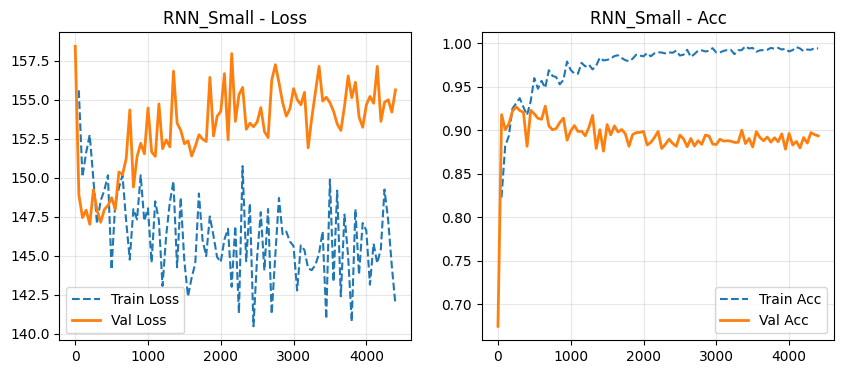

Best RNN config found: {'name': 'RNN_Fast', 'hidden_dim': 128, 'lr': 0.001, 'dropout': 0.2, 'weight_decay': 0.0}


,Model,Hidden,LR,Drop,WD,Best Val Loss,Best Val Acc
0,RNN_Fast,128,0.0010,0.2,0.00000,146.7444,91.60%
1,RNN_Balanced,256,0.0010,0.3,0.00001,148.2767,89.87%
2,RNN_Conservative,128,0.0005,0.4,0.00001,147.8444,84.96%
3,RNN_Small,64,0.0010,0.2,0.00000,147.0158,92.18%


In [40]:
if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

EPOCHS_GRID = 5
criterion = nn.BCEWithLogitsLoss().to(device)

experiments_rnn = [
    {
        "name": "RNN_Fast",
        "hidden_dim": 128,
        "lr": 1e-3,
        "dropout": 0.2,
        "weight_decay": 0.0
    },
    {
        "name": "RNN_Balanced",
        "hidden_dim": 256,
        "lr": 1e-3,
        "dropout": 0.3,
        "weight_decay": 1e-5
    },
    {
        "name": "RNN_Conservative",
        "hidden_dim": 128,
        "lr": 5e-4,
        "dropout": 0.4,
        "weight_decay": 1e-5
    },
    {
        "name": "RNN_Small",
        "hidden_dim": 64,
        "lr": 1e-3,
        "dropout": 0.2,
        "weight_decay": 0.0
    }
]

results_table_rnn = []
best_valid_loss_rnn = float('inf')
best_config_rnn = {}
best_hist_rnn = None

for exp in experiments_rnn:
    print(f"\n{'='*60}")
    print(f"Starting: {exp['name']}")
    print(f"{'='*60}")

    net = RNN(vocab_size=len(vocab), embedding_dim=300, hidden_dim=exp['hidden_dim'], num_layers=2,
              num_classes=1,dropout=exp['dropout'], embedding_weights=embedding_weights, bidirectional=True).to(device)

    optimizer = optim.Adam(net.parameters(), lr=exp['lr'], weight_decay=exp['weight_decay'])

    hist = train_engine(net=net, train_data_loader=train_loader_final, test_data_loader=val_loader_final,
                        optimizer=optimizer, criterion=criterion, num_epochs=20, name=exp['name'], device=device)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.plot(hist['train_steps'], hist['train_loss'], label='Train Loss', linestyle='--')
    plt.plot(hist['val_steps'], hist['val_loss'], label='Val Loss', linewidth=2)
    plt.title(f"{exp['name']} - Loss")
    plt.legend(); plt.grid(True, alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(hist['train_steps'], hist['train_acc'], label='Train Acc', linestyle='--')
    plt.plot(hist['val_steps'], hist['val_acc'], label='Val Acc', linewidth=2)
    plt.title(f"{exp['name']} - Acc")
    plt.legend(); plt.grid(True, alpha=0.3)
    plt.show()

    best_val_loss_in_run = min(hist['val_loss'])
    best_idx = hist['val_loss'].index(best_val_loss_in_run)
    val_acc_at_best_loss = hist['val_acc'][best_idx]

    results_table_rnn.append({
        "Model": exp['name'],
        "Hidden": exp['hidden_dim'],
        "LR": exp['lr'],
        "Drop": exp['dropout'],
        "WD": exp['weight_decay'],
        "Best Val Loss": f"{best_val_loss_in_run:.4f}",
        "Best Val Acc": f"{val_acc_at_best_loss*100:.2f}%"
    })

    if best_val_loss_in_run < best_valid_loss_rnn:
        best_valid_loss_rnn = best_val_loss_in_run
        best_config_rnn = exp.copy()
        best_hist_rnn = copy.deepcopy(hist)

print("=" * 60)
print(f"Best RNN config found: {best_config_rnn}")

if results_table_rnn:
    df_results_rnn = pd.DataFrame(results_table_rnn)
    try:
        from IPython.display import display
        display(df_results_rnn)
    except:
        print(df_results_rnn)

>>> [Final_RNN_Run Val] Loss: 0.56819, Acc: 57.73%
[Final_RNN_Run] [Ep: 1, Step: 49] Train Loss: 0.30241, Acc: 84.72%
>>> [Final_RNN_Run Val] Loss: 0.39363, Acc: 81.17%
[Final_RNN_Run] [Ep: 1, Step: 99] Train Loss: 0.22024, Acc: 89.31%
>>> [Final_RNN_Run Val] Loss: 0.34500, Acc: 82.60%
[Final_RNN_Run] [Ep: 1, Step: 149] Train Loss: 0.18094, Acc: 90.78%
>>> [Final_RNN_Run Val] Loss: 0.38595, Acc: 79.96%
[Final_RNN_Run] [Ep: 1, Step: 199] Train Loss: 0.23840, Acc: 88.22%
>>> [Final_RNN_Run Val] Loss: 0.35163, Acc: 82.46%
[Final_RNN_Run] [Ep: 2, Step: 249] Train Loss: 0.20613, Acc: 89.76%
>>> [Final_RNN_Run Val] Loss: 0.34302, Acc: 80.80%
[Final_RNN_Run] [Ep: 2, Step: 299] Train Loss: 0.19423, Acc: 90.59%
>>> [Final_RNN_Run Val] Loss: 0.57074, Acc: 78.50%
[Final_RNN_Run] [Ep: 2, Step: 349] Train Loss: 0.23117, Acc: 88.84%
>>> [Final_RNN_Run Val] Loss: 0.36919, Acc: 83.67%
[Final_RNN_Run] [Ep: 2, Step: 399] Train Loss: 0.20935, Acc: 89.59%
>>> [Final_RNN_Run Val] Loss: 0.40821, Acc: 80.37%

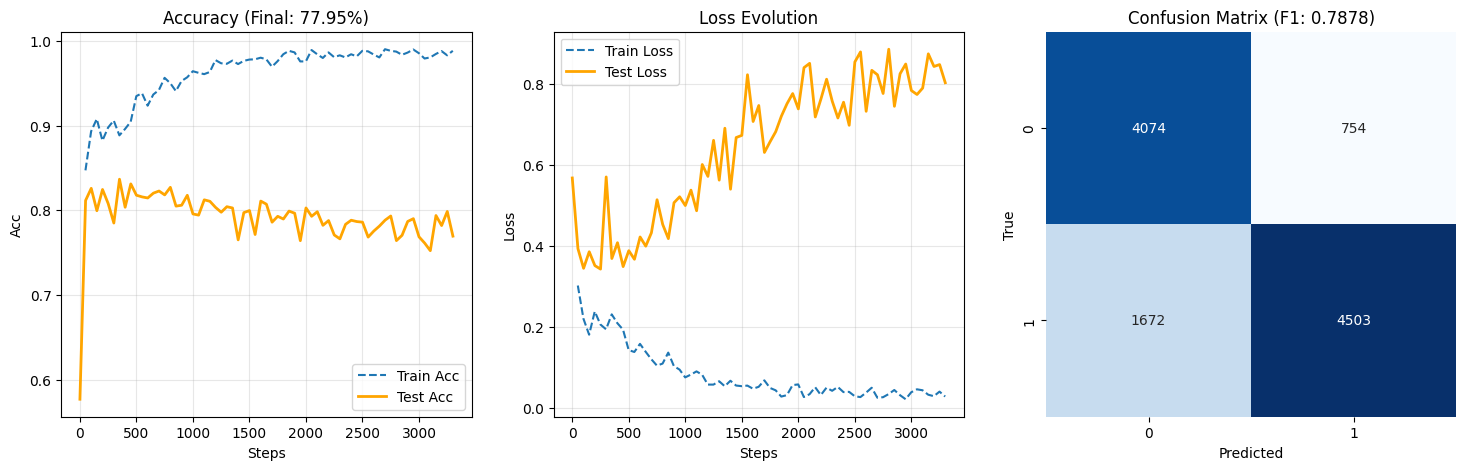

✅ REZULTAT BUN: 77.95% Acuratețe. RNN-ul cu Pooling funcționează!


In [41]:
best_config = {
    'hidden_dim': 256,
    'num_layers': 2,
    'dropout': 0.4,
    'bidirectional': True,
    'lr': 0.0005
}

final_model = RNN(vocab_size=len(vocab),embedding_dim=300,hidden_dim=best_config['hidden_dim'],
                  num_layers=best_config['num_layers'],num_classes=1,dropout=best_config['dropout'],
                  embedding_weights=embedding_weights,bidirectional=best_config['bidirectional']).to(device)

neg_count = (y_train_final == 0).sum().item()
pos_count = (y_train_final == 1).sum().item()

if pos_count > 0:
    pos_weight_val = torch.tensor([neg_count / pos_count]).to(device)
else:
    pos_weight_val = torch.tensor([1.0]).to(device)


optimizer = optim.Adam(final_model.parameters(), lr=best_config['lr'], weight_decay=1e-5)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_val).to(device)

history = train_engine(net=final_model, train_data_loader=train_loader_final, test_data_loader=test_loader_final,
                       optimizer=optimizer, criterion=criterion, num_epochs=15,  name="Final_RNN_Run", device=device)

final_model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in test_loader_final:
        inputs = batch[0].to(device)
        labels = batch[1].to(device)

        outputs = final_model(inputs).squeeze(1)
        preds = torch.round(torch.sigmoid(outputs))

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
from sklearn.metrics import accuracy_score, f1_score
acc_final = accuracy_score(all_labels, all_preds)
f1_final = f1_score(all_labels, all_preds)

plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.plot(history['train_steps'], history['train_acc'], label='Train Acc', linestyle='--')
plt.plot(history['val_steps'], history['val_acc'], label='Test Acc', linewidth=2, color='orange')
plt.title(f"Accuracy (Final: {acc_final*100:.2f}%)")
plt.xlabel("Steps"); plt.ylabel("Acc"); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(history['train_steps'], history['train_loss'], label='Train Loss', linestyle='--')
plt.plot(history['val_steps'], history['val_loss'], label='Test Loss', linewidth=2, color='orange')
plt.title("Loss Evolution")
plt.xlabel("Steps"); plt.ylabel("Loss"); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 3, 3)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f"Confusion Matrix (F1: {f1_final:.4f})")
plt.xlabel("Predicted"); plt.ylabel("True")

plt.show()

print("="*50)
if acc_final > 0.65:
    print(f"✅ REZULTAT BUN: {acc_final*100:.2f}% Acuratețe. RNN-ul cu Pooling funcționează!")
else:
    print(f"⚠️ REZULTAT MEDIU: {acc_final*100:.2f}%. Verifică dacă datele sunt curate.")
print("="*50)

In [56]:
import random
import pandas as pd

random.seed(42)

def random_deletion(text, p=0.15):
    if not isinstance(text, str) or not text.strip():
        return ""

    words = text.split()

    if len(words) == 1:
        return text

    new_words = []
    for word in words:
        if random.random() > p:
            new_words.append(word)

    if len(new_words) == 0:
        return random.choice(words)

    return " ".join(new_words)

def random_swap(text, n=1):
    if not isinstance(text, str) or not text.strip():
        return ""

    words = text.split()

    if len(words) < 2:
        return text

    for _ in range(n):
        idx1, idx2 = random.sample(range(len(words)),2)
        words[idx1], words[idx2] = words[idx2], words[idx1]

    return " ".join(words)

In [57]:
train_df_raw, val_df_raw = train_test_split(
    train_loader,
    test_size=0.2,
    random_state=42,
    stratify=train_loader['label']
)

In [58]:
augmented_rows = []

for idx, row in train_loader.iterrows():
    text = row['text_clean']
    label = row['label']

    augmented_rows.append({'text_clean': text, 'label': label})

    text_swap = random_swap(text, 1)
    augmented_rows.append({'text_clean': text_swap, 'label': label})

    text_del = random_deletion(text, 0.15)
    augmented_rows.append({'text_clean': text_del, 'label': label})

train_df_aug = pd.DataFrame(augmented_rows)
# Amestecăm datele
train_df_aug = train_df_aug.sample(frac=1, random_state=42).reset_index(drop=True)

In [60]:
if 'tokens' not in test_loader.columns:
    test_loader['tokens'] = tokenize(test_loader['text_clean'])

# Ensure 'tokens' column exists for augmented and validation data
if 'tokens' not in train_df_aug.columns:
    train_df_aug['tokens'] = tokenize(train_df_aug['text_clean'])
if 'tokens' not in val_df_raw.columns:
    val_df_raw['tokens'] = tokenize(val_df_raw['text_clean'])

# Construim vocabularul pe baza tuturor datelor pentru a evita <UNK>
all_words = []
for tokens_list in train_df_aug['tokens']:
    all_words.extend(tokens_list)
for tokens_list in val_df_raw['tokens']:
    all_words.extend(tokens_list)
for tokens_list in test_loader['tokens']:
    all_words.extend(tokens_list)

word_counts = Counter(all_words)
vocab = {"<PAD>": 0, "<UNK>": 1}

for word, count in word_counts.items():
    if count >= 2: # Păstrăm cuvinte care apar de cel puțin 2 ori
        vocab[word] = len(vocab)

print(f"Mărime Vocabular Nou: {len(vocab)}")

# 4. CONVERSIE LA INDICI & EMBEDDINGS
# ==========================================
# Convertim tokenii în numere
train_df_aug['indices'] = train_df_aug['tokens'].apply(lambda x: text_to_indices(x, max_len=100))
val_df_raw['indices'] = val_df_raw['tokens'].apply(lambda x: text_to_indices(x, max_len=100))
test_loader['indices'] = test_loader['tokens'].apply(lambda x: text_to_indices(x, max_len=100))

Mărime Vocabular Nou: 58729


In [61]:
if 'ft_model' in globals():
    embedding_weights = create_embedding_matrix(vocab, ft_model)
    print("Matricea de embeddings a fost actualizată.")
else:
    print("⚠️ ATENȚIE: 'ft_model' nu este în memorie. Asigură-te că rulezi FastText înainte.")

Matricea de embeddings a fost actualizată.


In [62]:
X_train = torch.tensor(list(train_df_aug['indices'].values), dtype=torch.long)
y_train = torch.tensor(list(train_df_aug['label'].values), dtype=torch.float32)

X_val = torch.tensor(list(val_df_raw['indices'].values), dtype=torch.long)
y_val = torch.tensor(list(val_df_raw['label'].values), dtype=torch.float32)

X_test = torch.tensor(list(test_loader['indices'].values), dtype=torch.long)
y_test = torch.tensor(list(test_loader['label'].values), dtype=torch.float32)

print(f"Forme Finale -> Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

BATCH_SIZE = 64

# Dataset-uri
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

# Loaders
train_loader_final = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader_final = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader_final = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

Forme Finale -> Train: torch.Size([264630, 100]), Val: torch.Size([17642, 100]), Test: torch.Size([11003, 100])


In [66]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import copy
import pandas as pd

# 1. Configurare
if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

# Fiind dataset-ul mai mare, 5 epoci sunt suficiente pentru grid
EPOCHS_GRID = 1
criterion = nn.BCEWithLogitsLoss().to(device)

# 2. Definim Experimentele (Aceleași ca înainte pentru consistență)
experiments_lstm = [
    {
        "name": "LSTM_Fast_Learning",
        "hidden_dim": 128,
        "lr": 1e-3,
        "dropout": 0.2,
        "weight_decay": 0.0
    },
    {
        "name": "LSTM_Balanced",
        "hidden_dim": 256,
        "lr": 1e-3,
        "dropout": 0.3,
        "weight_decay": 1e-5
    },
    {
        "name": "LSTM_Deep_Reg",
        "hidden_dim": 256,
        "lr": 5e-4,
        "dropout": 0.4,
        "weight_decay": 1e-5
    },
    {
        "name": "LSTM_Simple",
        "hidden_dim": 64,
        "lr": 1e-3,
        "dropout": 0.2,
        "weight_decay": 0.0
    }
]

results_table = []
best_valid_loss = float('inf')
best_config = {}
best_hist = None

print(f"🚀 Start Grid Search pe Dataset AUGMENTAT...")
print(f"Dimensiune Train Loader: {len(train_loader_final.dataset)}")

for exp in experiments_lstm:
    print(f"\n{'='*60}")
    print(f"Starting: {exp['name']}")
    print(f"{'='*60}")

    # --- FOLOSIM CLASA CU POOLING (Cea mai importantă parte!) ---
    # Asigură-te că LSTM_Pooling este definită în memorie din pașii anteriori
    net = LSTM(
        vocab_size=len(vocab),
        embedding_dim=300,
        hidden_dim=exp['hidden_dim'],
        num_layers=2,
        num_classes=1,
        dropout=exp['dropout'],
        embedding_weights=embedding_weights,
        bidirectional=True
    ).to(device)

    optimizer = optim.Adam(net.parameters(), lr=exp['lr'], weight_decay=exp['weight_decay'])

    # Antrenare pe datele augmentate (train_loader_final)
    hist = train_engine(
        net=net,
        train_data_loader=train_loader_final,
        test_data_loader=val_loader_final,
        optimizer=optimizer,
        criterion=criterion,
        num_epochs=1,
        name=exp['name'],
        device=device
    )

    # Plotare
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.plot(hist['train_steps'], hist['train_loss'], label='Train Loss', linestyle='--')
    plt.plot(hist['val_steps'], hist['val_loss'], label='Val Loss', linewidth=2)
    plt.title(f"{exp['name']} - Loss")
    plt.legend(); plt.grid(True, alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(hist['train_steps'], hist['train_acc'], label='Train Acc', linestyle='--')
    plt.plot(hist['val_steps'], hist['val_acc'], label='Val Acc', linewidth=2)
    plt.title(f"{exp['name']} - Acc")
    plt.legend(); plt.grid(True, alpha=0.3)
    plt.show()

    # Colectare rezultate
    best_val_loss_in_run = min(hist['val_loss'])
    best_idx = hist['val_loss'].index(best_val_loss_in_run)
    val_acc_at_best_loss = hist['val_acc'][best_idx]

    results_table.append({
        "Model": exp['name'],
        "Hidden": exp['hidden_dim'],
        "LR": exp['lr'],
        "Drop": exp['dropout'],
        "WD": exp['weight_decay'],
        "Best Val Loss": f"{best_val_loss_in_run:.4f}",
        "Best Val Acc": f"{val_acc_at_best_loss*100:.2f}%"
    })

    if best_val_loss_in_run < best_valid_loss:
        best_valid_loss = best_val_loss_in_run
        best_config = exp.copy()
        best_hist = copy.deepcopy(hist)

print("=" * 60)
print(f"Best config found (Augmented): {best_config}")

if results_table:
    df_results = pd.DataFrame(results_table)
    try:
        from IPython.display import display
        display(df_results)
    except:
        print(df_results)

🚀 Start Grid Search pe Dataset AUGMENTAT...
Dimensiune Train Loader: 264630

Starting: LSTM_Fast_Learning
>>> [LSTM_Fast_Learning Val] Loss: 0.66740, Acc: 61.35%
[LSTM_Fast_Learning] [Ep: 1, Step: 49] Train Loss: 0.66249, Acc: 62.12%
>>> [LSTM_Fast_Learning Val] Loss: 0.66726, Acc: 61.35%
[LSTM_Fast_Learning] [Ep: 1, Step: 99] Train Loss: 0.67113, Acc: 60.75%
>>> [LSTM_Fast_Learning Val] Loss: 0.66738, Acc: 61.35%
[LSTM_Fast_Learning] [Ep: 1, Step: 149] Train Loss: 0.66255, Acc: 62.62%
>>> [LSTM_Fast_Learning Val] Loss: 0.66724, Acc: 61.35%
[LSTM_Fast_Learning] [Ep: 1, Step: 199] Train Loss: 0.67049, Acc: 60.91%
>>> [LSTM_Fast_Learning Val] Loss: 0.66901, Acc: 61.35%
[LSTM_Fast_Learning] [Ep: 1, Step: 249] Train Loss: 0.66580, Acc: 62.00%
>>> [LSTM_Fast_Learning Val] Loss: 0.66747, Acc: 61.35%
[LSTM_Fast_Learning] [Ep: 1, Step: 299] Train Loss: 0.66675, Acc: 61.66%
>>> [LSTM_Fast_Learning Val] Loss: 0.66722, Acc: 61.35%
[LSTM_Fast_Learning] [Ep: 1, Step: 349] Train Loss: 0.67099, Acc: 

KeyboardInterrupt: 

<Figure size 1200x500 with 0 Axes>

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

final_lstm = LSTM(vocab_size=len(vocab), embedding_dim=300, hidden_dim=best_config['hidden_dim'], num_layers=2,
                  num_classes=1, dropout=best_config['dropout'], embedding_weights=embedding_weights, bidirectional=True).to(device)

optimizer = optim.Adam(final_lstm.parameters(), lr=best_config['lr'])
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

history = train_engine(net=final_lstm, train_data_loader=train_loader_final, test_data_loader=test_loader_final,
                       optimizer=optimizer, criterion=criterion, scheduler=scheduler, num_epochs=5, name="Final_Run_on_Test", device=device)

final_lstm.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in test_loader_final:
        inputs = batch[0].to(device)
        labels = batch[1].to(device)

        outputs = final_lstm(inputs).squeeze(1)
        preds = torch.round(torch.sigmoid(outputs))

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
final_test_acc = history['val_acc'][-1]
final_test_loss = history['val_loss'][-1]

plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.plot(history['train_steps'], history['train_acc'], label='Train Acc', linestyle='--')
plt.plot(history['val_steps'], history['val_acc'], label='Test Acc', linewidth=2, color='orange')
plt.title(f"Accuracy (Test Final: {final_test_acc*100:.2f}%)")
plt.xlabel("Steps")
plt.ylabel("Acc")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(history['train_steps'], history['train_loss'], label='Train Loss', linestyle='--')
plt.plot(history['val_steps'], history['val_loss'], label='Test Loss', linewidth=2, color='orange')
plt.title(f"Loss (Test Final: {final_test_loss:.4f})")
plt.xlabel("Steps")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (Test Set)')

plt.tight_layout()
plt.show()

print(f"\n✅ GATA! Modelul final a obținut {final_test_acc*100:.2f}% pe setul de TEST.")

In [ ]:
if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

EPOCHS_GRID = 1
criterion = nn.BCEWithLogitsLoss().to(device)

experiments_rnn = [
    {
        "name": "RNN_Fast",
        "hidden_dim": 128,
        "lr": 1e-3,
        "dropout": 0.2,
        "weight_decay": 0.0
    },
    {
        "name": "RNN_Balanced",
        "hidden_dim": 256,
        "lr": 1e-3,
        "dropout": 0.3,
        "weight_decay": 1e-5
    },
    {
        "name": "RNN_Conservative",
        "hidden_dim": 128,
        "lr": 5e-4,
        "dropout": 0.4,
        "weight_decay": 1e-5
    },
    {
        "name": "RNN_Small",
        "hidden_dim": 64,
        "lr": 1e-3,
        "dropout": 0.2,
        "weight_decay": 0.0
    }
]

results_table_rnn = []
best_valid_loss_rnn = float('inf')
best_config_rnn = {}
best_hist_rnn = None

for exp in experiments_rnn:
    print(f"\n{'='*60}")
    print(f"Starting: {exp['name']}")
    print(f"{'='*60}")

    net = RNN(vocab_size=len(vocab), embedding_dim=300, hidden_dim=exp['hidden_dim'], num_layers=2,
              num_classes=1,dropout=exp['dropout'], embedding_weights=embedding_weights, bidirectional=True).to(device)

    optimizer = optim.Adam(net.parameters(), lr=exp['lr'], weight_decay=exp['weight_decay'])

    hist = train_engine(net=net, train_data_loader=train_loader_final, test_data_loader=val_loader_final,
                        optimizer=optimizer, criterion=criterion, num_epochs=1, name=exp['name'], device=device)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.plot(hist['train_steps'], hist['train_loss'], label='Train Loss', linestyle='--')
    plt.plot(hist['val_steps'], hist['val_loss'], label='Val Loss', linewidth=2)
    plt.title(f"{exp['name']} - Loss")
    plt.legend(); plt.grid(True, alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(hist['train_steps'], hist['train_acc'], label='Train Acc', linestyle='--')
    plt.plot(hist['val_steps'], hist['val_acc'], label='Val Acc', linewidth=2)
    plt.title(f"{exp['name']} - Acc")
    plt.legend(); plt.grid(True, alpha=0.3)
    plt.show()

    best_val_loss_in_run = min(hist['val_loss'])
    best_idx = hist['val_loss'].index(best_val_loss_in_run)
    val_acc_at_best_loss = hist['val_acc'][best_idx]

    results_table_rnn.append({
        "Model": exp['name'],
        "Hidden": exp['hidden_dim'],
        "LR": exp['lr'],
        "Drop": exp['dropout'],
        "WD": exp['weight_decay'],
        "Best Val Loss": f"{best_val_loss_in_run:.4f}",
        "Best Val Acc": f"{val_acc_at_best_loss*100:.2f}%"
    })

    if best_val_loss_in_run < best_valid_loss_rnn:
        best_valid_loss_rnn = best_val_loss_in_run
        best_config_rnn = exp.copy()
        best_hist_rnn = copy.deepcopy(hist)

print("=" * 60)
print(f"Best RNN config found: {best_config_rnn}")

if results_table_rnn:
    df_results_rnn = pd.DataFrame(results_table_rnn)
    try:
        from IPython.display import display
        display(df_results_rnn)
    except:
        print(df_results_rnn)

In [ ]:
best_config = {
    'hidden_dim': 256,
    'num_layers': 2,
    'dropout': 0.4,
    'bidirectional': True,
    'lr': 0.0005
}

final_model = RNN(vocab_size=len(vocab),embedding_dim=300,hidden_dim=best_config['hidden_dim'],
                  num_layers=best_config['num_layers'],num_classes=1,dropout=best_config['dropout'],
                  embedding_weights=embedding_weights,bidirectional=best_config['bidirectional']).to(device)

neg_count = (y_train_final == 0).sum().item()
pos_count = (y_train_final == 1).sum().item()

if pos_count > 0:
    pos_weight_val = torch.tensor([neg_count / pos_count]).to(device)
else:
    pos_weight_val = torch.tensor([1.0]).to(device)


optimizer = optim.Adam(final_model.parameters(), lr=best_config['lr'], weight_decay=1e-5)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_val).to(device)

history = train_engine(net=final_model, train_data_loader=train_loader_final, test_data_loader=test_loader_final,
                       optimizer=optimizer, criterion=criterion, num_epochs=15,  name="Final_RNN_Run", device=device)

final_model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in test_loader_final:
        inputs = batch[0].to(device)
        labels = batch[1].to(device)

        outputs = final_model(inputs).squeeze(1)
        preds = torch.round(torch.sigmoid(outputs))

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
from sklearn.metrics import accuracy_score, f1_score
acc_final = accuracy_score(all_labels, all_preds)
f1_final = f1_score(all_labels, all_preds)

plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.plot(history['train_steps'], history['train_acc'], label='Train Acc', linestyle='--')
plt.plot(history['val_steps'], history['val_acc'], label='Test Acc', linewidth=2, color='orange')
plt.title(f"Accuracy (Final: {acc_final*100:.2f}%)")
plt.xlabel("Steps"); plt.ylabel("Acc"); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(history['train_steps'], history['train_loss'], label='Train Loss', linestyle='--')
plt.plot(history['val_steps'], history['val_loss'], label='Test Loss', linewidth=2, color='orange')
plt.title("Loss Evolution")
plt.xlabel("Steps"); plt.ylabel("Loss"); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 3, 3)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f"Confusion Matrix (F1: {f1_final:.4f})")
plt.xlabel("Predicted"); plt.ylabel("True")

plt.show()

print("="*50)
if acc_final > 0.65:
    print(f"✅ REZULTAT BUN: {acc_final*100:.2f}% Acuratețe. RNN-ul cu Pooling funcționează!")
else:
    print(f"⚠️ REZULTAT MEDIU: {acc_final*100:.2f}%. Verifică dacă datele sunt curate.")
print("="*50)